# Radiatively Corrected Non-Minimal Higgs Inflation
## Numerical predictions, current ACT/SPT screening, radiative-correction ML and future CMB tensor tests

**The question:** Which regions of Prescription I or Prescription II agree with current ACT/SPT screens, which parameters control the differences, and what *hypothetical future measurement of* $r$ would help distinguish them?

This notebook **does not rescan** the inflationary equations. It reads `data/Prescription_I_ALL.dat` and `data/Prescription_II_ALL.dat`, retains the full gray numerical backgrounds, and produces paired **Prescription I (left) / Prescription II (right)** physics, machine-learning, and forecast figures. Every figure is shown inline in Jupyter and exported as **PNG and PDF**.

The ML analysis includes **Random Forest ACT/SPT acceptance classification**, a four-category matched-input comparison, **ExtraTrees and MLP** regression of $(n_s,\log_{10}r,\alpha_s)$, **permutation importance**, a **radiative-correction sign analysis**, and **ML-assisted future-$r$ diagnostics**. **No active learning** is included.

### Publication visualization rules
Large and bold x/y labels, **bold major/minor axis ticks and tick labels**, thick spines, large markers, strong legends, and one shared $N_*$ colorbar where applicable. $0.95\leq n_s\leq1$ and $0\leq r\leq0.05$ for the main $(n_s,r)$ figure; **no zoom figures**.

### Folder layout
```
project/
    Higgs_ML_Current_Future_Radiative.ipynb
    data/
        Prescription_I_ALL.dat
        Prescription_II_ALL.dat
```
If those files are unavailable during a preview, included **example reference data (8,087 branches)** are used and explicitly labeled. Place your new scan data in `data/` and rerun all cells to obtain the large-scan results.

## 1. Model, bounds, and meaning of the comparison

For $F(\phi)=1+\xi\phi^2/M_P^2$ and $\beta=\kappa/\lambda$, the two prescriptions use

$$V_I(\phi)=\frac{\phi^4}{24F(\phi)^2}\left[\lambda+24\kappa\ln\!\left(\frac{\phi}{M_P\sqrt{F(\phi)}}\right)\right],$$
$$V_{II}(\phi)=\frac{\phi^4}{24F(\phi)^2}\left[\lambda+24\kappa\ln\!\left(\frac{\phi}{M_P}\right)\right].$$

The scanner already solved the Einstein-frame slow-roll system and retained trajectories with $50\le N_*\le60$, $A_s=2.43\times10^{-9}$, and the first slow-roll breakdown at $\max(\epsilon,|\eta|)=1$.

**Rectangular screening intervals (not the full 2D CMB likelihood):**
$$\mathrm{P\! -\!ACT\! -\!LB\! -\!BK18}:\quad |n_s-0.9743|\le0.0068,$$
$$\mathrm{P\! -\!ACT\! -\!SPT}:\quad |n_s-0.9684|\le0.0060,\qquad 0\le r<0.036.$$

The phenomenological theory screen uses $0<\lambda<1$, a `loop_control` flag and rejection of `near_stationary_precision` cases. Gray points show **all** finite successful branches, including those failing these additional screens. The $\alpha_s$ plot includes the adopted *illustrative* $-0.004\le\alpha_s\le0.017$ bounds; these are **not** a dataset-specific combined running likelihood.

**Crucial caveat:** An accepted scan fraction or classifier score is **not** the probability that a prescription is true. A definitive comparison requires priors, all relevant data, and a full cosmological likelihood.

In [1]:
# Install packages if needed (once):
# %pip install numpy pandas matplotlib scipy scikit-learn

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import AutoMinorLocator, FixedLocator, FuncFormatter, NullLocator
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             balanced_accuracy_score, ConfusionMatrixDisplay,
                             roc_auc_score, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.inspection import permutation_importance
from scipy.special import logsumexp
from scipy.stats import norm
import warnings

SEED = 20261108
FILE_I = None  # Example: Path(r'D:\my_scans\Prescription_I_ALL.dat')
FILE_II = None # Example: Path(r'D:\my_scans\Prescription_II_ALL.dat')

ACT_CENTER, ACT_HALF = 0.9743, 0.0068
SPT_CENTER, SPT_HALF = 0.9684, 0.0060
R_LIMIT = 0.036
ALPHA_LOW, ALPHA_HIGH = -0.004, 0.017

# If preferred, switch to True for a logarithmic r axis. No extra zoom figure is generated.
R_LOG = False
R_MAX = 0.05
NS_RANGE = (0.95, 1.00)

# Practical ML limits for an ordinary laptop; physics figures always use full scan data.
MAX_ML_TRAIN = 90_000
MAX_ML_TEST = 25_000
N_TREES = 120
N_REG_TREES = 100
RUN_MLP = True
RUN_FUTURE_FORECAST = True
REG_MAX_TRAIN_PER_P = 18000
REG_MAX_TEST_PER_P = 5500
ML_N_FIXED = 55.0  # e-fold value at which to draw ML-score maps
ML_MAP_GRID = 125

# Bold, large publication styling.
plt.rcParams.update({
    'font.family':'DejaVu Sans', 'mathtext.fontset':'dejavusans',
    'font.size':19, 'axes.titlesize':25, 'axes.titleweight':'bold',
    'axes.labelsize':30, 'axes.labelweight':'bold',
    'xtick.labelsize':19, 'ytick.labelsize':19,
    'axes.linewidth':2.5, 'legend.fontsize':16,
    'xtick.direction':'in', 'ytick.direction':'in',
    'xtick.top':True, 'ytick.right':True,
    'xtick.major.size':11, 'xtick.major.width':2.5,
    'ytick.major.size':11, 'ytick.major.width':2.5,
    'xtick.minor.size':6, 'xtick.minor.width':1.8,
    'ytick.minor.size':6, 'ytick.minor.width':1.8,
    'figure.facecolor':'white', 'savefig.facecolor':'white',
})
PALETTE = {
  'gray':'#77818d', 'ACT':'#238b6f','SPT':'#3a7cba',
  'ink':'#253343','running':'#bd6d22',
}
CMAP = 'viridis'
NNORM = colors.Normalize(vmin=50,vmax=60)
print('Publication style loaded. R_LOG =',R_LOG)

Publication style loaded. R_LOG = False


## 2. Load the two full `.dat` files and inspect all variables

In [2]:
def locate_data(roman, explicit=None):
    name=f'Prescription_{roman}_ALL.dat'
    if explicit is not None:
        p=Path(explicit).expanduser()
        if not p.is_file():raise FileNotFoundError(p)
        return p
    for candidate in (Path('data')/name, Path(name),
                      Path(f'Higgs_Prescription_{roman}_Scan')/'dat'/name,
                      Path('example_reference_data')/name):
        if candidate.is_file():return candidate
    raise FileNotFoundError(f'{name} missing: place in data/ or configure FILE_{roman}.')

def parse_flag(d,name,default=False):
    if name not in d:return pd.Series(default,index=d.index,dtype=bool)
    a=d[name]
    if pd.api.types.is_bool_dtype(a):return a.fillna(False).astype(bool)
    if pd.api.types.is_numeric_dtype(a):return pd.to_numeric(a,errors='coerce').fillna(0).ne(0)
    return a.astype('string').str.strip().str.lower().isin(['true','1','yes'])

def parse_scan(path,prescription):
    path=Path(path)
    if path.suffix.lower()=='.csv':
        d=pd.read_csv(path,low_memory=False)
    else:
        with path.open('r',encoding='utf8') as f:first=f.readline().strip()
        if not first.startswith('#'):
            raise ValueError(f'{path}: expected first line with # column names')
        names=first.lstrip('#').strip().split()
        d=pd.read_csv(path,sep=r'\s+',comment='#',header=None,
                      names=names,low_memory=False)
    d=d.rename(columns={'lambda_':'lambda','n_s':'ns','N_star':'N',
                        'beta_ratio':'beta'})
    required=['sample_id','xi','beta','N','lambda','kappa','ns','r','alpha_s']
    missing=[q for q in required if q not in d]
    if missing:raise ValueError(f'{path.name}: missing columns {missing}')
    for q in required:d[q]=pd.to_numeric(d[q],errors='coerce')
    good=np.isfinite(d[required].to_numpy(dtype=float)).all(axis=1)
    d=d.loc[good].copy()
    d['sample_id']=d.sample_id.astype('int64')
    d['prescription']=prescription
    d['theory_screen']=(d['lambda'].gt(0)&d['lambda'].lt(1)&
        parse_flag(d,'loop_control')&~parse_flag(d,'near_stationary_precision'))
    d['ACT95']=(d.theory_screen & (d.ns-ACT_CENTER).abs().le(ACT_HALF) &
                d.r.ge(0)&d.r.lt(R_LIMIT))
    d['SPT95']=(d.theory_screen & (d.ns-SPT_CENTER).abs().le(SPT_HALF) &
                d.r.ge(0)&d.r.lt(R_LIMIT))
    d['BOTH95']=d.ACT95 & d.SPT95
    return d

input_i=locate_data('I',FILE_I)
input_ii=locate_data('II',FILE_II)
IS_PREVIEW='example_reference_data' in str(input_i) or 'example_reference_data' in str(input_ii)
output_dir=Path('outputs_reference_preview' if IS_PREVIEW else 'outputs_user_scan')
FIGS=output_dir/'figures'
TABLES=output_dir/'tables'
FIGS.mkdir(parents=True,exist_ok=True)
TABLES.mkdir(parents=True,exist_ok=True)
DATA={1:parse_scan(input_i,1),2:parse_scan(input_ii,2)}
print('DATA MODE:', 'REFERENCE PREVIEW — NOT the full user scan' if IS_PREVIEW else 'YOUR SCAN')
print('Inputs:',input_i.resolve(),'\n       ',input_ii.resolve())
print('Variables:',', '.join(DATA[1].columns))
for p in (1,2):
    d=DATA[p]
    print(f'Prescription {"I" if p==1 else "II"}: {len(d):,} numerical branches, '
          f'{d.sample_id.nunique():,} inputs, {int(d.theory_screen.sum()):,} theory-screened, '
          f'{int(d.ACT95.sum()):,} ACT-screened, {int(d.SPT95.sum()):,} SPT-screened')

DATA MODE: YOUR SCAN
Inputs: D:\InfaltionaryProjects\non-minimal\Final_Scanning_Dataand_ML_Nov\Higgs_ML_Project\data\Prescription_I_ALL.dat 
        D:\InfaltionaryProjects\non-minimal\Final_Scanning_Dataand_ML_Nov\Higgs_ML_Project\data\Prescription_II_ALL.dat
Variables: sample_id, prescription, xi, beta, N, xi_stratum, beta_stratum, N_stratum, end_id, n_end_candidates, roll_direction, end_epsilon, x_end, x_star, phi_end_GeV, phi_star_GeV, eps_end, eta_end, eps_star, eta_star, zeta2_star, ns, r, alpha_s, As, lambda, kappa, Vstar_Mp4, loop_fraction_max, lambda_perturbative, loop_control, near_stationary_precision, strict_phi_window, paper_plot_window, theory_screen, ACT95, SPT95, both95, negative_lambda_flag, BOTH95
Prescription I: 320,281 numerical branches, 299,767 inputs, 228,889 theory-screened, 28,535 ACT-screened, 93,922 SPT-screened
Prescription II: 374,151 numerical branches, 299,773 inputs, 229,513 theory-screened, 24,880 ACT-screened, 47,104 SPT-screened


## 3. Thick, bold publication plotting helpers and PDF export

In [3]:
def display_and_save(fig,stem):
    pdf=FIGS/f'{stem}.pdf'
    png=FIGS/f'{stem}.png'
    fig.savefig(pdf,bbox_inches='tight',dpi=220)
    fig.savefig(png,bbox_inches='tight',dpi=170)
    print(f'Saved: {pdf.name} and {png.name}')
    plt.show()
    plt.close(fig)

def bold_ticks(ax):
    ax.minorticks_on()
    ax.tick_params(which='major',length=11,width=2.5,labelsize=19)
    ax.tick_params(which='minor',length=6,width=1.8)
    for lab in ax.get_xticklabels()+ax.get_yticklabels():
        lab.set_fontweight('bold')

def ns_bands(ax,axis='x'):
    shade=ax.axvspan if axis=='x' else ax.axhspan
    line=ax.axvline if axis=='x' else ax.axhline
    shade(ACT_CENTER-ACT_HALF,ACT_CENTER+ACT_HALF,alpha=.24,
          color='#65c49b',zorder=0)
    shade(SPT_CENTER-SPT_HALF,SPT_CENTER+SPT_HALF,alpha=.23,
          color='#72aee3',zorder=0)
    line(ACT_CENTER,lw=1.7,ls=':',color=PALETTE['ACT'],zorder=.5)
    line(SPT_CENTER,lw=1.7,ls=':',color=PALETTE['SPT'],zorder=.5)

def draw_scan_points(ax,d,x,y):
    # Do not restrict the gray background to theory-screened points.
    finite=d.loc[np.isfinite(d[[x,y]].to_numpy(dtype=float)).all(axis=1)]
    if x=='xi':finite=finite.loc[finite.xi.gt(0)]
    if R_LOG and y=='r':finite=finite.loc[finite.r.gt(0)]
    ax.scatter(finite[x],finite[y],s=23,c=PALETTE['gray'],alpha=.21,
               linewidths=0,rasterized=True,zorder=1)
    screen=finite.loc[finite.theory_screen]
    ax.scatter(screen[x],screen[y],s=48,c=screen.N,cmap=CMAP,norm=NNORM,
               alpha=.48,linewidths=0,rasterized=True,zorder=2)
    selected=finite.loc[finite.ACT95|finite.SPT95]
    ax.scatter(selected[x],selected[y],s=79,c=selected.N,cmap=CMAP,norm=NNORM,
               alpha=.94,edgecolors='#1f3035',linewidths=.33,
               rasterized=True,zorder=3)

def legend_for(include_r=False,include_running=False):
    h=[Line2D([],[],ls='',marker='o',markersize=9,color=PALETTE['gray'],
              label='All numerical branches'),
       Line2D([],[],ls='',marker='o',markersize=10,color='#3c9d7b',
              label='Theory-screened'),
       Line2D([],[],ls='',marker='o',markersize=12,color='#e5c657',
              markeredgecolor='#1f3035',label='ACT/SPT-screened'),
       Patch(facecolor='#65c49b',alpha=.5,label='P–ACT–LB–BK18 (95%)'),
       Patch(facecolor='#72aee3',alpha=.5,label='P–ACT–SPT (95%)')]
    if include_r:h.append(Line2D([],[],ls='--',lw=2.3,color=PALETTE['ink'],label=r'$r<0.036$'))
    if include_running:h.append(Line2D([],[],ls='-.',lw=2.3,color=PALETTE['running'],
                                       label=r'Adopted $\alpha_s$ limits'))
    return h

def fmt_decades(x,pos):
    if abs(x)<1e-100:return '$0$'
    exp=int(round(np.log10(abs(x))))
    return rf'${"-" if x<0 else ""}10^{{{exp}}}$'

def make_pair(stem,x,y,xlab,ylab,*,ns_axis='x',xscale=None,rline=False,alpha_limits=False,
              ylim=None):
    fig,axs=plt.subplots(1,2,figsize=(20.4,8.5),sharex=True,sharey=True)
    for ax,p in zip(axs,[1,2]):
        d=DATA[p]
        if ns_axis:ns_bands(ax,ns_axis)
        if rline:ax.axhline(R_LIMIT,color=PALETTE['ink'],ls='--',lw=2.2,zorder=.5)
        if alpha_limits:
            ax.axhspan(ALPHA_LOW,ALPHA_HIGH,alpha=.12,color='#e6a963',zorder=0)
            for edge in (ALPHA_LOW,ALPHA_HIGH):
                ax.axhline(edge,color=PALETTE['running'],ls='-.',lw=2.2,zorder=.5)
            ax.axhline(0,color='#687583',ls='--',lw=1.25,zorder=.5)
        draw_scan_points(ax,d,x,y)
        if xscale=='log':ax.set_xscale('log')
        elif xscale=='signed-log':
            vals=np.abs(d[x].to_numpy(dtype=float))
            vals=vals[np.isfinite(vals)&(vals>0)]
            small=max(float(np.percentile(vals,10)),1e-35) if len(vals) else 1e-15
            ax.set_xscale('symlog',linthresh=small,linscale=.8)
        if rline:
            ax.set_ylim((1e-5 if R_LOG else 0),R_MAX)
            if R_LOG:ax.set_yscale('log')
        if ylim is not None:ax.set_ylim(*ylim)
        if x=='ns':ax.set_xlim(*NS_RANGE)
        if y=='ns':ax.set_ylim(*NS_RANGE)
        ax.set_title('Prescription I' if p==1 else 'Prescription II',pad=16,fontweight='bold')
        ax.set_xlabel(xlab,labelpad=10,fontweight='bold',fontsize=31)
        ax.set_ylabel(ylab,labelpad=9,fontweight='bold',fontsize=31)
        bold_ticks(ax)
        ax.grid(False)
    if xscale=='signed-log':
        decades=([-14,-8] if x=='kappa' else [-12,-6,0])
        lo,hi=axs[0].get_xlim()
        ticks=sorted(set([z for e in decades for z in (-10.**e,10.**e) if lo<z<hi]
                        +([0] if lo<0<hi else [])))
        for ax in axs:
            ax.xaxis.set_major_locator(FixedLocator(ticks))
            ax.xaxis.set_major_formatter(FuncFormatter(fmt_decades))
            ax.xaxis.set_minor_locator(NullLocator())
            bold_ticks(ax)
    legend=legend_for(rline,alpha_limits)
    fig.legend(handles=legend,ncol=3,loc='upper center',
               bbox_to_anchor=(.465,.985),frameon=True,framealpha=.98,
               edgecolor='#263b4a',facecolor='white',
               prop={'weight':'bold','size':17},markerscale=1.3,
               handlelength=2.1,columnspacing=1.1)
    fig.subplots_adjust(left=.075,right=.88,bottom=.14,top=.75,wspace=.18)
    bar=fig.colorbar(cm.ScalarMappable(norm=NNORM,cmap=CMAP),ax=axs,
                     fraction=.027,pad=.024,aspect=24)
    bar.set_label(r'$N_*$ (e-folds)',fontsize=25,fontweight='bold',labelpad=12)
    bar.ax.tick_params(labelsize=19,width=1.8,length=7)
    for tick in bar.ax.get_yticklabels():tick.set_fontweight('bold')
    display_and_save(fig,stem)

## Figure 1. $n_s$ versus $r$

The horizontal axis is **exactly** $0.95\leq n_s\leq1.00$, the vertical axis is bounded above by $r=0.05$, and the current illustrative tensor screen $r<0.036$ is shown. `R_LOG=True` can be selected in the configuration cell if a logarithmic tensor axis is useful; it does **not** create an additional zoom plot.

Saved: Fig_01_ns_r.pdf and Fig_01_ns_r.png


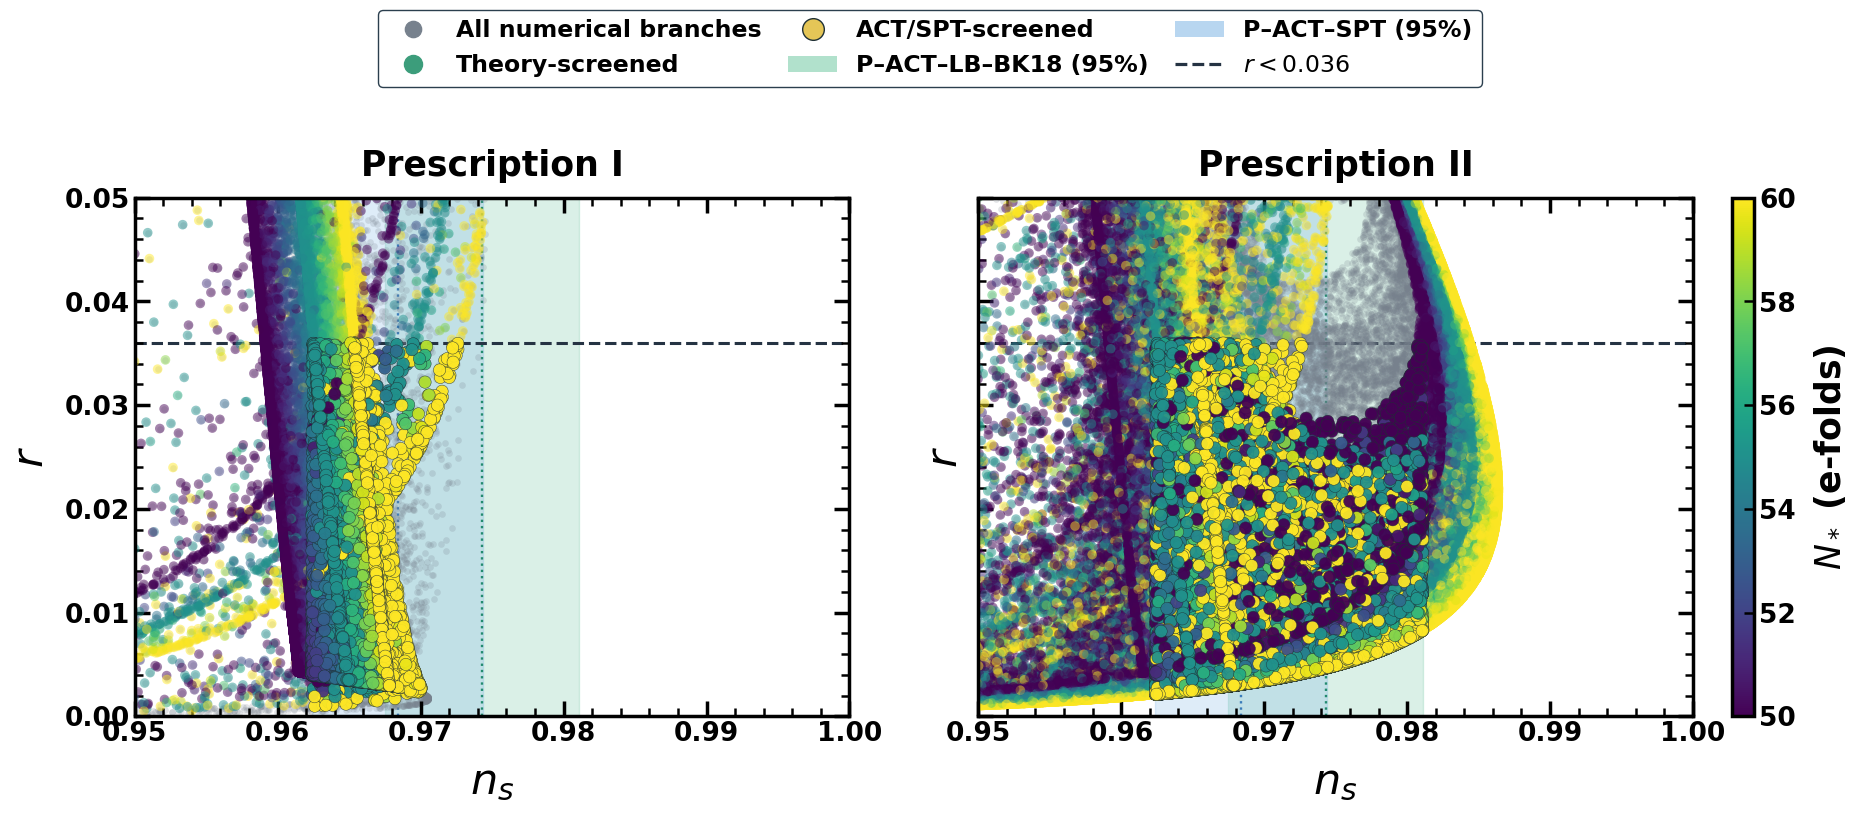

In [4]:
make_pair('Fig_01_ns_r','ns','r',r'$n_s$',r'$r$',rline=True)

## Figure 2. $\kappa$ versus $n_s$

Positive and negative loop coefficients are retained on the signed-logarithmic horizontal axis, and $0.95\leq n_s\leq1$ applies vertically.

Saved: Fig_02_kappa_ns.pdf and Fig_02_kappa_ns.png


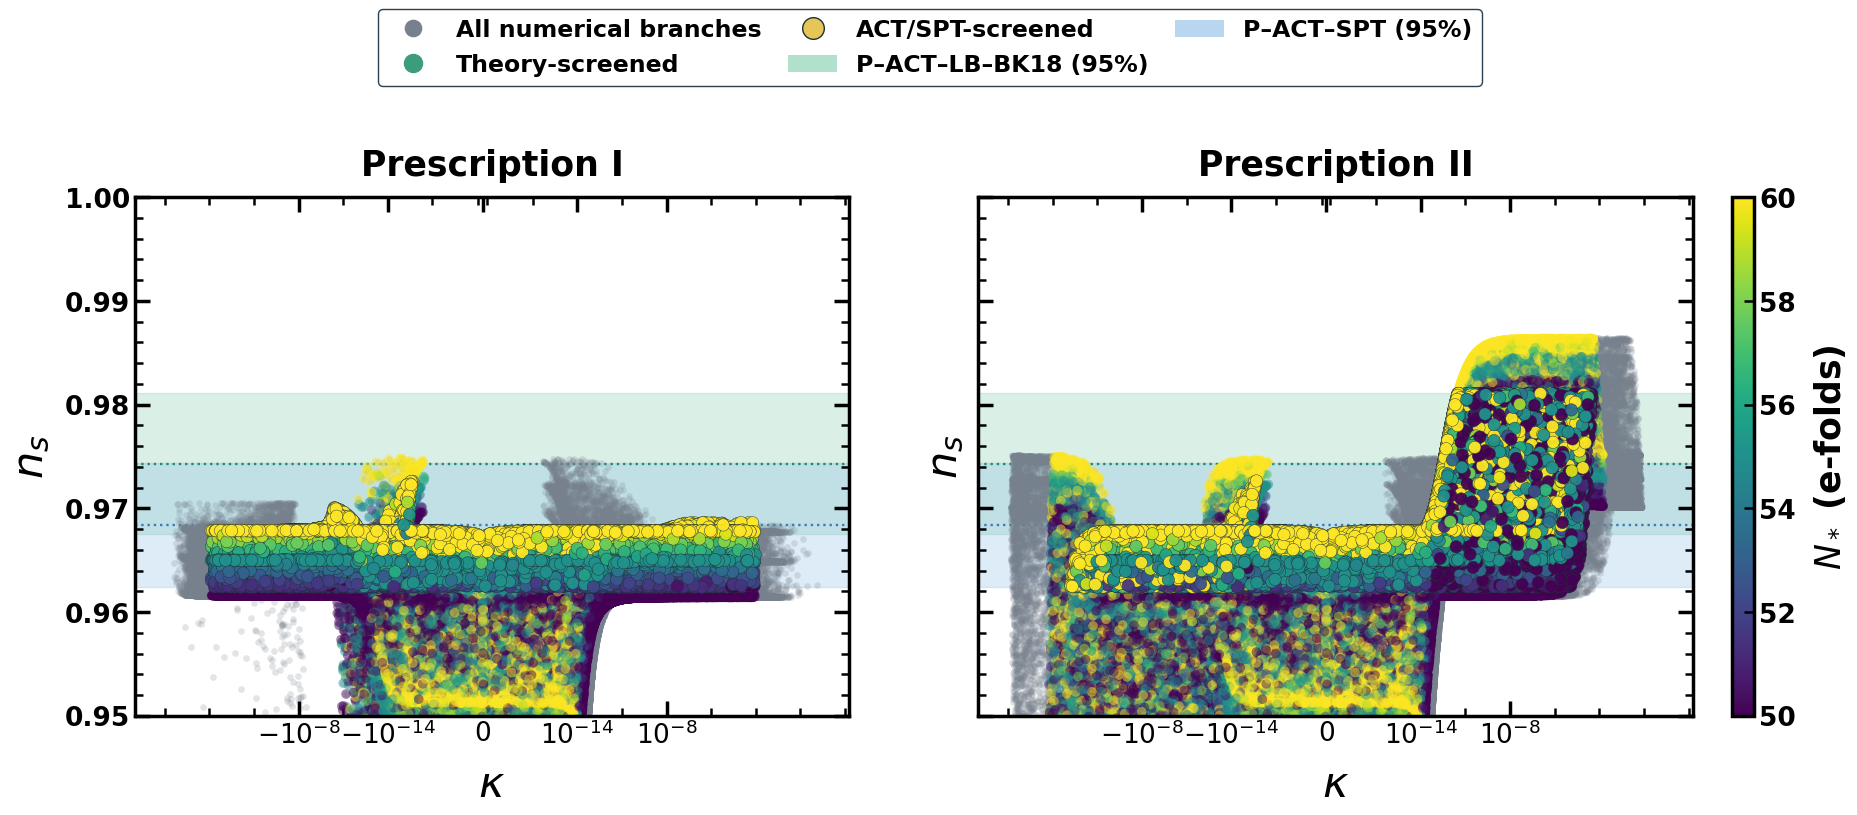

In [5]:
make_pair('Fig_02_kappa_ns','kappa','ns',r'$\kappa$',r'$n_s$',ns_axis='y',xscale='signed-log')

## Figure 3. $\lambda$ versus $n_s$

The full gray sample can include negative renormalized $\lambda$ branches, while the colored theoretical screen keeps $0<\lambda<1$.

Saved: Fig_03_lambda_ns.pdf and Fig_03_lambda_ns.png


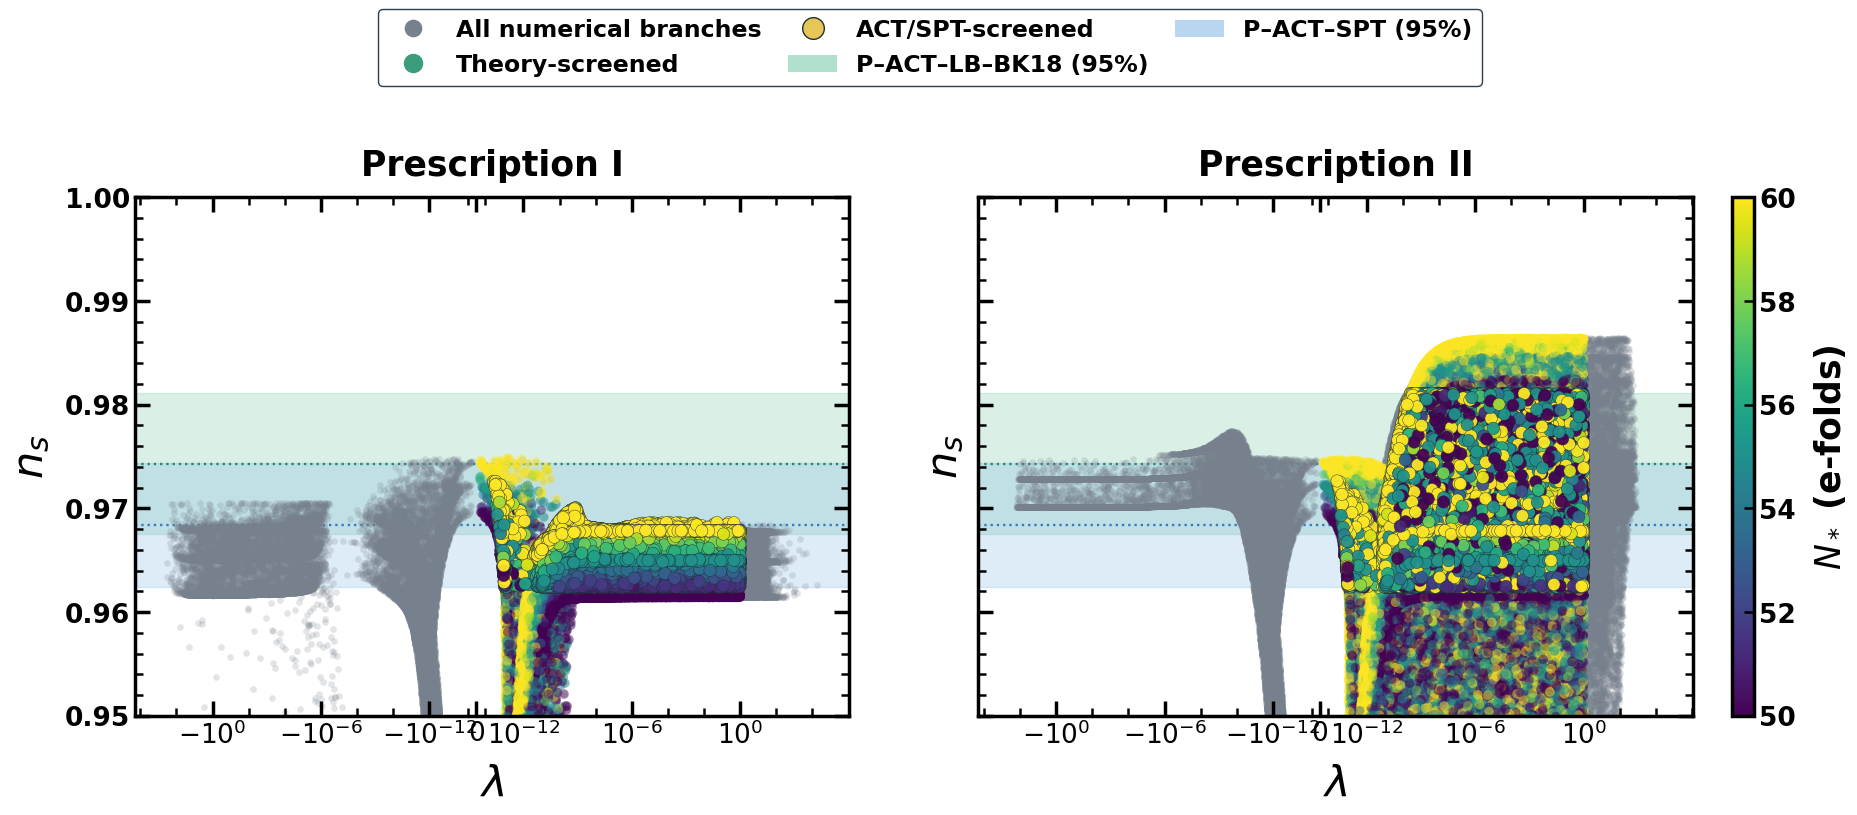

In [6]:
make_pair('Fig_03_lambda_ns','lambda','ns',r'$\lambda$',r'$n_s$',ns_axis='y',xscale='signed-log')

## Figure 4. $\alpha_s$ versus $n_s$

The figure displays the adopted running bounds $\alpha_s=-0.004$ and $\alpha_s=0.017$ and one common e-fold color bar. These bounds are **not** advertised as a dedicated joint ACT/SPT running likelihood.

Saved: Fig_04_alpha_ns.pdf and Fig_04_alpha_ns.png


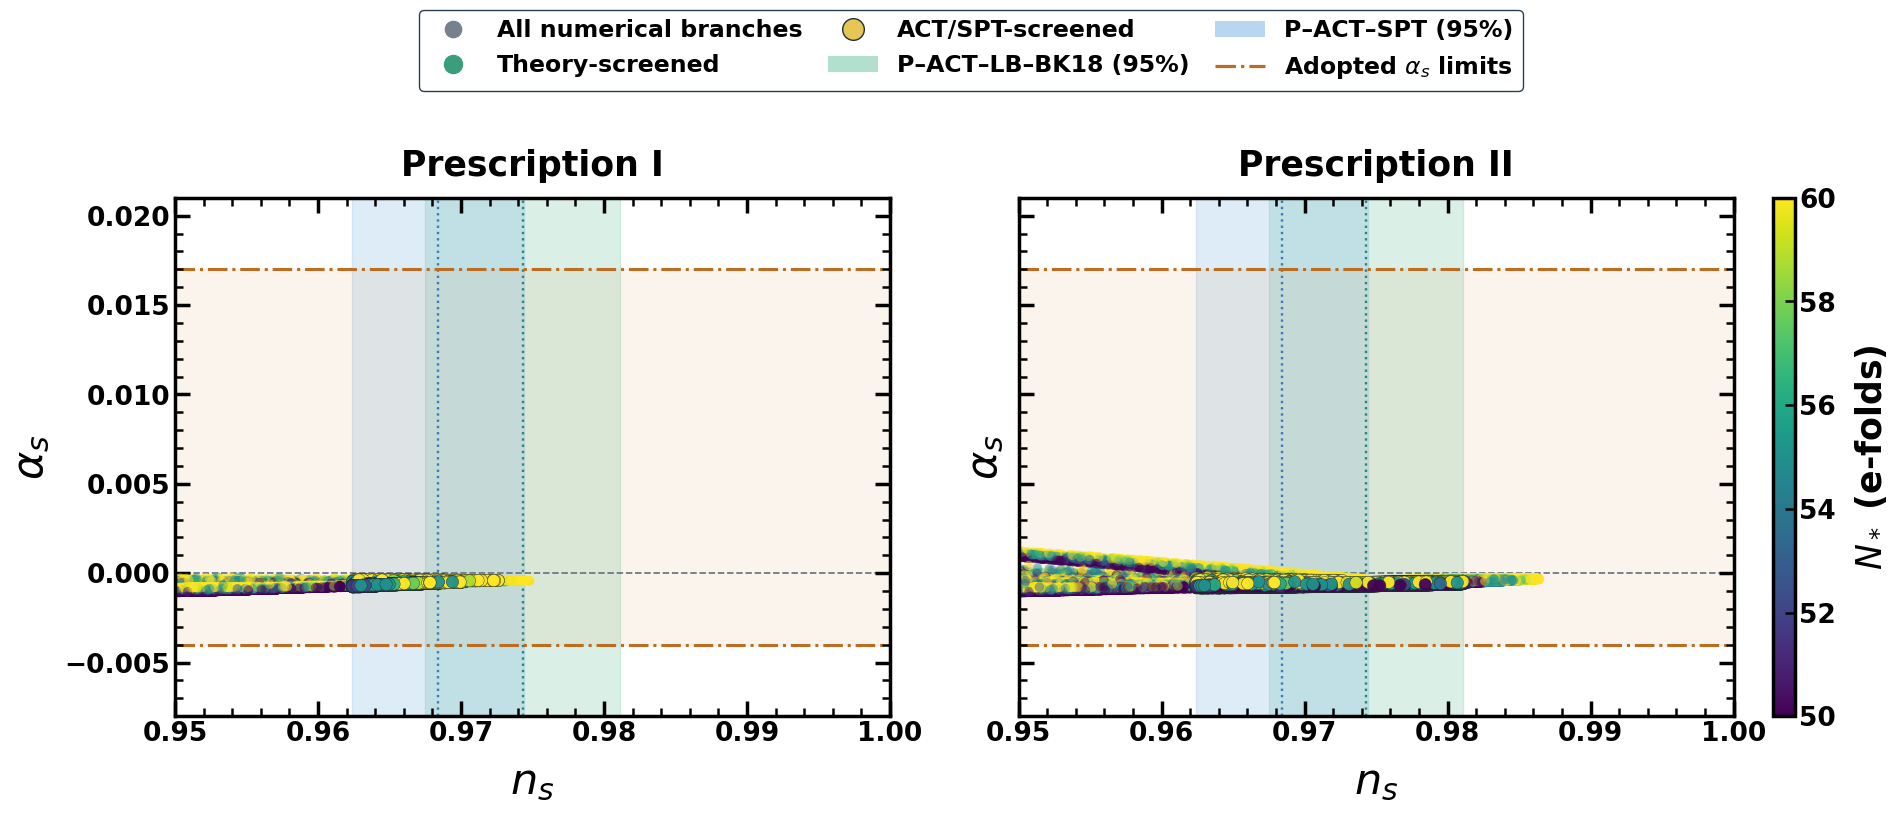

In [7]:
make_pair('Fig_04_alpha_ns','ns','alpha_s',r'$n_s$',r'$\alpha_s$',alpha_limits=True,ylim=(-.008,.021))

## Figure 5. $\xi$ versus $n_s$

Because the non-minimal coupling spans many orders of magnitude, the horizontal axis is logarithmic; all values of $n_s$ shown are in $[0.95,1]$.

Saved: Fig_05_xi_ns.pdf and Fig_05_xi_ns.png


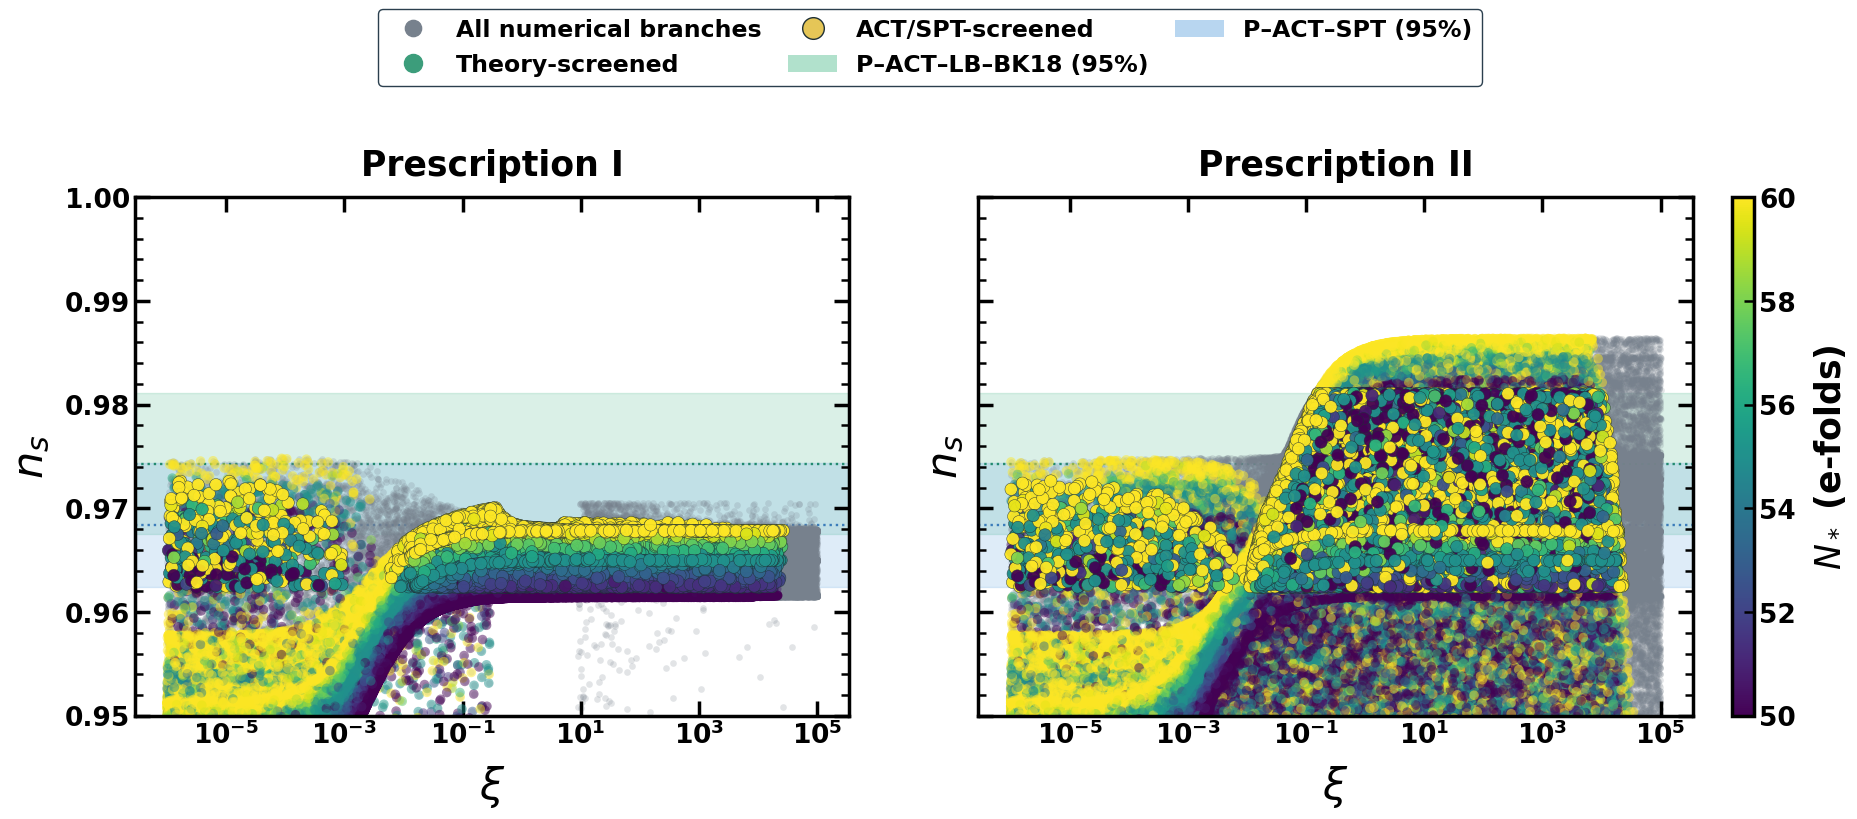

In [8]:
make_pair('Fig_05_xi_ns','xi','ns',r'$\xi$',r'$n_s$',ns_axis='y',xscale='log')

## 4. Input-level datasets and paired prescriptions

The exact solver can find **multiple inflationary branches** for one input $(\xi,\beta,N_*)$. For classification, each parameter input is labeled accepted if **at least one branch** passes the screen. This avoids falsely counting multiple solutions as independent random inputs.

For regression, we use one **explicit representative** theory-screened branch per prescription and input (smallest $r$). It is only a deterministic convention: near-inflection or multi-branch regions require a branch-aware surrogate for complete coverage.

The same `sample_id` must never occur in both training and testing datasets, including across prescriptions. The split below uses matched IDs and is held fixed across models.

In [9]:
def input_level(d):
    grp=d.groupby('sample_id',sort=False)
    pars=grp[['xi','beta','N']].first()
    flags=grp[['ACT95','SPT95','BOTH95','theory_screen']].any()
    flags.columns=['ACT_any','SPT_any','BOTH_any','THEORY_any']
    return pars.join(flags)

I=input_level(DATA[1]); II=input_level(DATA[2])
paired=I.join(II,how='inner',lsuffix='_I',rsuffix='_II')
match=(np.isclose(paired.xi_I,paired.xi_II,rtol=2e-6,atol=1e-15)&
       np.isclose(paired.beta_I,paired.beta_II,rtol=2e-6,atol=1e-15)&
       np.isclose(paired.N_I,paired.N_II,rtol=2e-6,atol=1e-9))
paired=paired.loc[match].copy()
for flag in ['ACT','SPT']:
    a=paired[f'{flag}_any_I'].to_numpy(bool)
    b=paired[f'{flag}_any_II'].to_numpy(bool)
    paired[f'{flag}_outcome']=np.select([a&~b,~a&b,a&b],[1,2,3],default=0)
paired.to_csv(TABLES/'matched_input_flags.csv')
print(f'Matched, consistent random inputs: {len(paired):,}')
for name in ['ACT','SPT']:
    print(name,dict(zip(['neither','I only','II only','both'],np.bincount(paired[f'{name}_outcome'],minlength=4))))

# Representative solution: theory-screened branch first, then lowest r.
representatives={}
for p in (1,2):
    d=DATA[p].sort_values(['sample_id','theory_screen','r'],ascending=[True,False,True])
    representatives[p]=d.drop_duplicates('sample_id').copy()
    representatives[p].to_csv(TABLES/f'representative_branches_{p}.csv',index=False)

def signed_log(beta):
    beta=np.asarray(beta,dtype=float)
    return np.sign(beta)*np.log10(1+np.abs(beta)/1e-10)

def feature_matrix(d):
    return pd.DataFrame({'log10_xi':np.log10(np.maximum(d['xi'].to_numpy(float),1e-30)),
        'signed_log_beta':signed_log(d['beta'].to_numpy(float)),
        'N_star':d['N'].to_numpy(float)}, index=d.index)

def axes_for_ml(ax,xlabel,ylabel,title=None):
    if title:ax.set_title(title,fontsize=25,weight='bold',pad=18)
    ax.set_xlabel(xlabel,fontsize=27,weight='bold',labelpad=10)
    ax.set_ylabel(ylabel,fontsize=26,weight='bold',labelpad=10)
    for side in ax.spines.values():side.set_linewidth(2.4)
    bold_ticks(ax)

Matched, consistent random inputs: 299,540
ACT {'neither': 257947, 'I only': 16713, 'II only': 13209, 'both': 11671}
SPT {'neither': 200542, 'I only': 51894, 'II only': 5290, 'both': 41814}


## 5. Current experiments: Random Forest ACT/SPT acceptance classification

The machine-learning inputs are $\mathbf x=(\log_{10}\xi,\operatorname{slog}(\beta),N_*)$; **no** observable $n_s$ or $r$ is used as an input. For each prescription and each survey screen, the Random Forest learns
$$\widehat p_{P,D}(\mathbf x)\simeq P_{\rm RF}(\text{at least one branch passes screen }D\mid\mathbf x,P).$$

It minimizes tree splitting impurity, and we evaluate held-out **F1, balanced accuracy, ROC-AUC**, and confusion matrices. The probability is with respect to the **scanner's design distribution**, not an observational model posterior.

The exact input-level categories (**neither, I only, II only, both**) are also saved for a transparent comparison.

In [10]:
rng=np.random.default_rng(SEED)
ids=np.arange(len(paired))
if len(ids)<100:raise RuntimeError('Not enough matched inputs for machine learning.')
train_ids,test_ids=train_test_split(ids,test_size=.25,random_state=SEED)
if len(train_ids)>MAX_ML_TRAIN:
    train_ids=rng.choice(train_ids,MAX_ML_TRAIN,replace=False)
if len(test_ids)>MAX_ML_TEST:
    test_ids=rng.choice(test_ids,MAX_ML_TEST,replace=False)
assert not set(train_ids)&set(test_ids)
Xpair=pd.DataFrame({'xi':paired.xi_I,'beta':paired.beta_I,'N':paired.N_I},index=paired.index)
X=feature_matrix(Xpair)
CLASSIFIERS={}; CLASS_RESULTS=[]; HELDOUT={}
for p,roman in [(1,'I'),(2,'II')]:
    for band in ('ACT','SPT'):
        target=paired[f'{band}_any_{roman}'].to_numpy(int)
        if len(np.unique(target[train_ids]))<2:
            print('Skipped one-class training:',roman,band);continue
        model=RandomForestClassifier(n_estimators=N_TREES,max_depth=16,
            min_samples_leaf=3,n_jobs=-1,class_weight='balanced_subsample',random_state=SEED+p+(band=='SPT'))
        model.fit(X.iloc[train_ids],target[train_ids])
        yp=model.predict(X.iloc[test_ids]);prob=model.predict_proba(X.iloc[test_ids])[:,list(model.classes_).index(1)]
        label=(p,band);CLASSIFIERS[label]=model
        HELDOUT[label]=(target[test_ids],yp,prob)
        row={'prescription':roman,'survey':band,'train_rows':len(train_ids),'test_rows':len(test_ids),
             'F1':f1_score(target[test_ids],yp,zero_division=0),
             'balanced_accuracy':balanced_accuracy_score(target[test_ids],yp),
             'ROC_AUC':roc_auc_score(target[test_ids],prob) if len(np.unique(target[test_ids]))==2 else np.nan}
        CLASS_RESULTS.append(row)
print(pd.DataFrame(CLASS_RESULTS).to_string(index=False,float_format=lambda v:f'{v:.4f}'))
pd.DataFrame(CLASS_RESULTS).to_csv(TABLES/'ML_classification_metrics.csv',index=False)

prescription survey  train_rows  test_rows     F1  balanced_accuracy  ROC_AUC
           I    ACT       90000      25000 0.9850             0.9947   0.9994
           I    SPT       90000      25000 0.9913             0.9948   0.9998
          II    ACT       90000      25000 0.9520             0.9929   0.9997
          II    SPT       90000      25000 0.9805             0.9936   0.9997


### Figure ML1 — ACT and SPT acceptance regions at $N_*=50,55,60$

Each row is a different e-fold slice and each column is a different prescription. Darker pixels mean the classifier predicts a larger **scan-defined acceptance frequency**. The exact eligible numerical points from a nearby e-fold interval are superposed as black-rimmed white markers. A wide, featureless pale area should **not** be interpreted as exclusion; it may simply be poorly sampled. For publication, validate any interesting patch using the exact inflation solver.

Saved: ML_01_ACT_acceptance_by_N.pdf and ML_01_ACT_acceptance_by_N.png


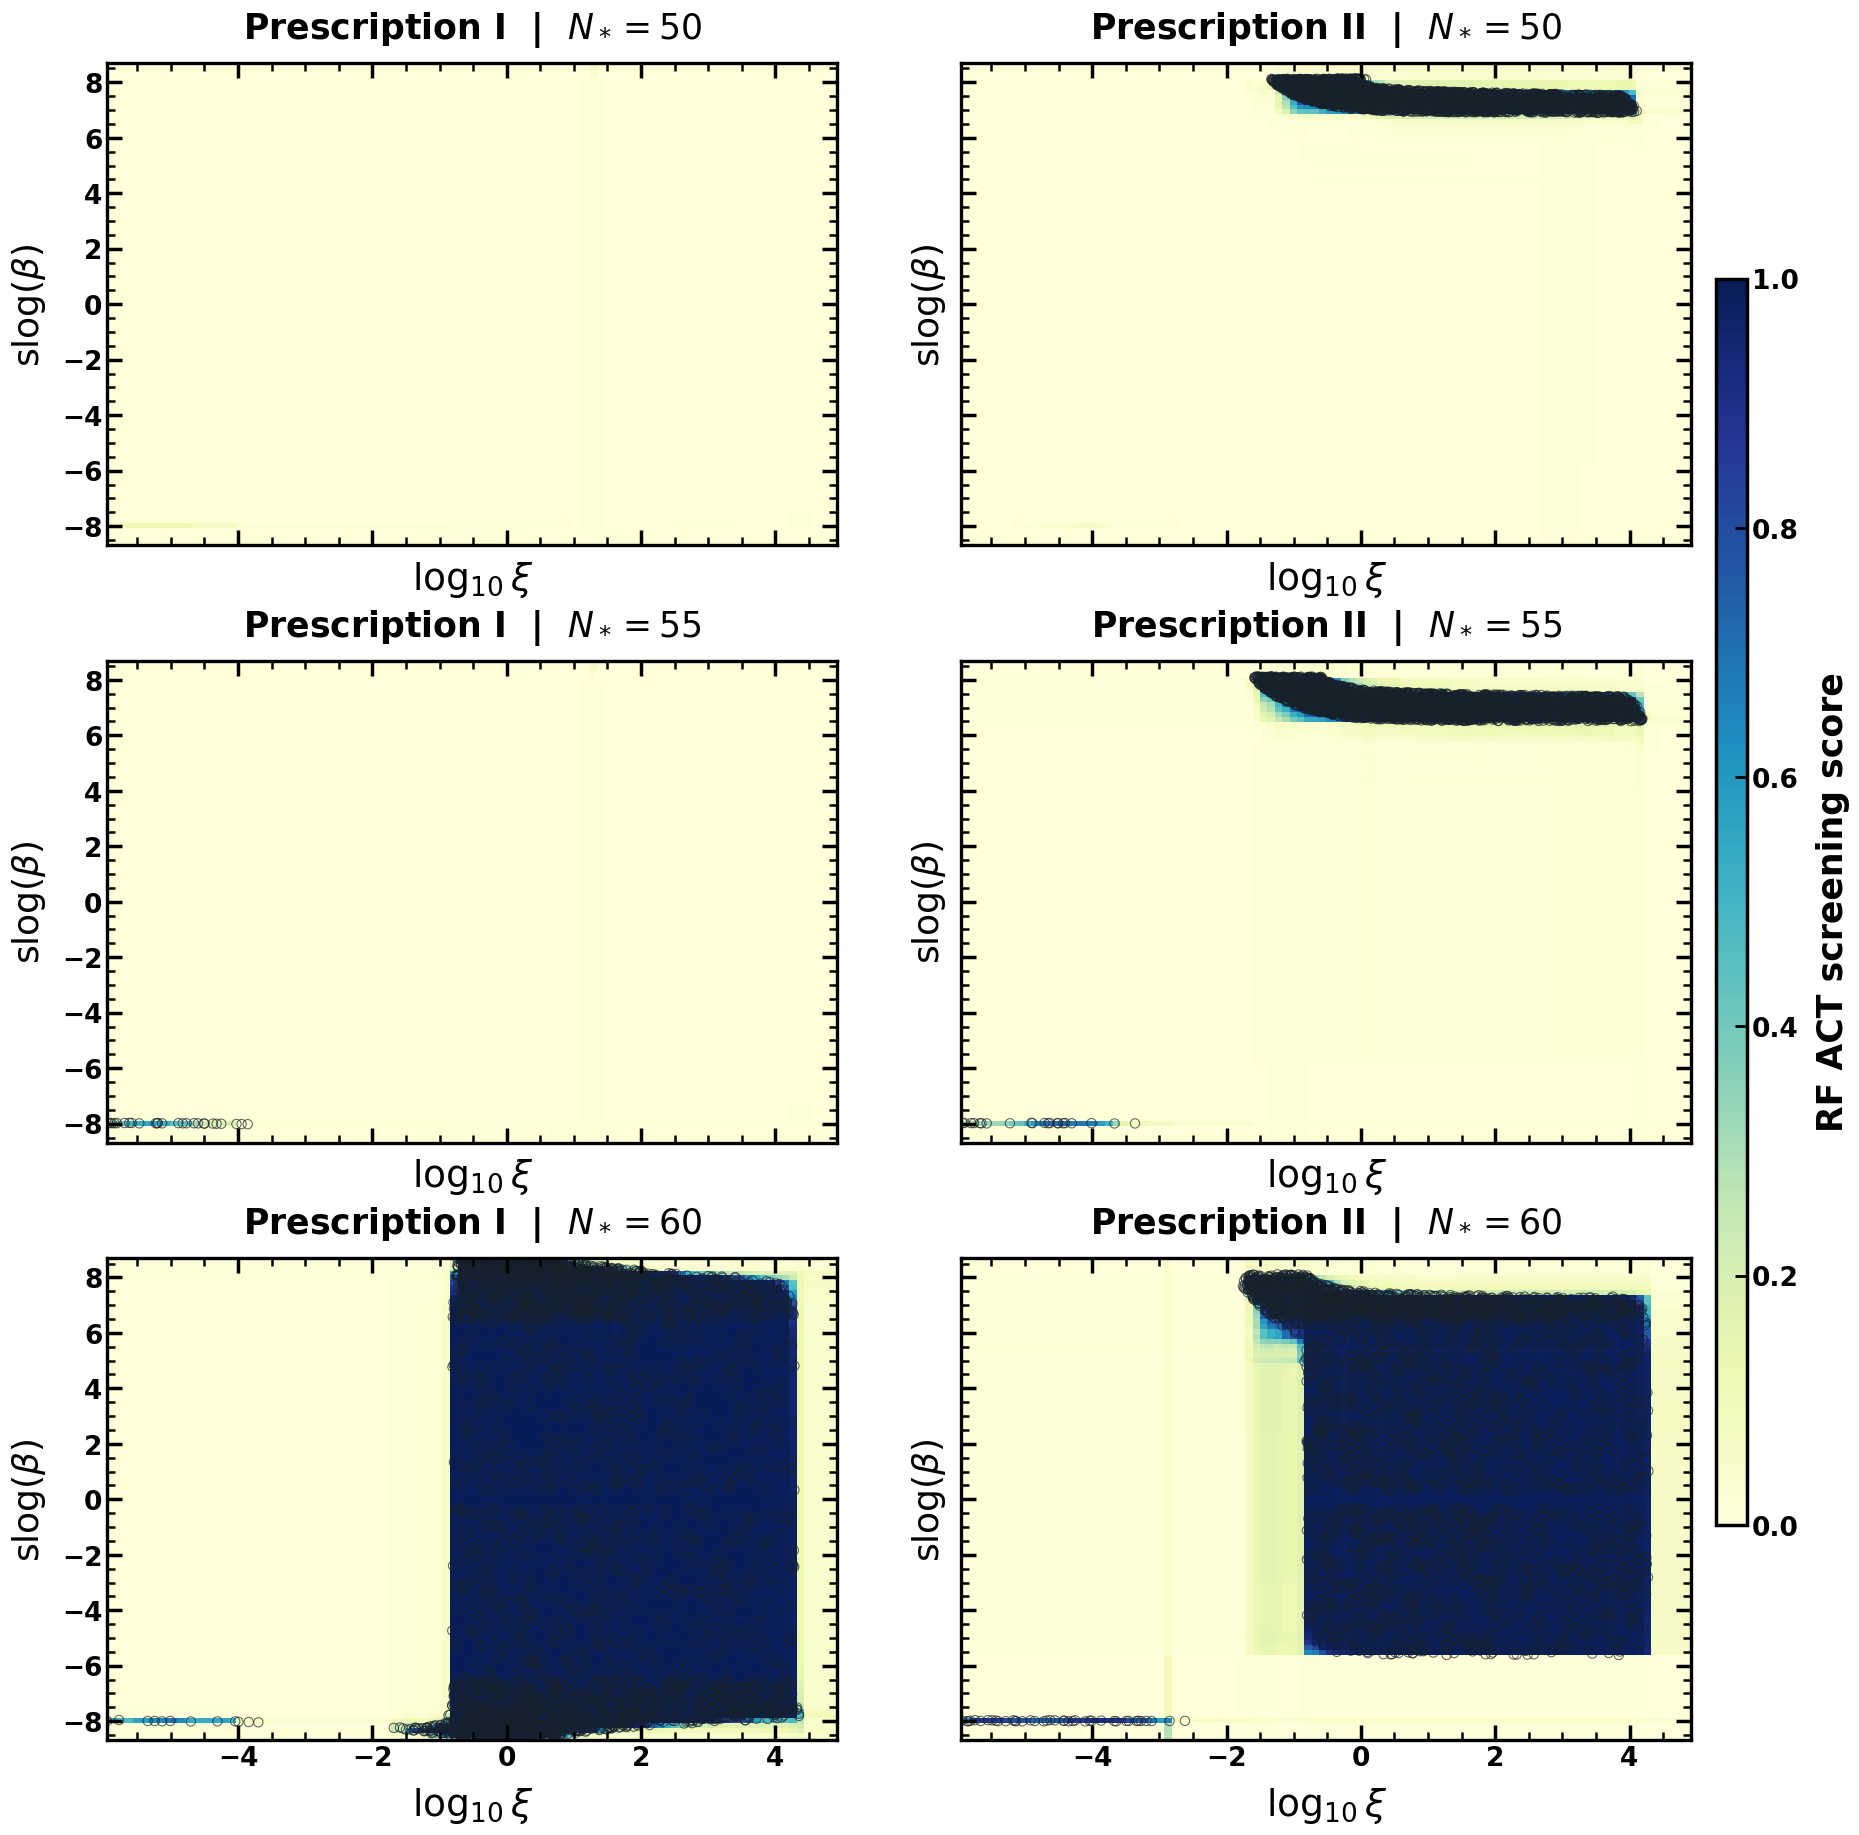

Saved: ML_01_SPT_acceptance_by_N.pdf and ML_01_SPT_acceptance_by_N.png


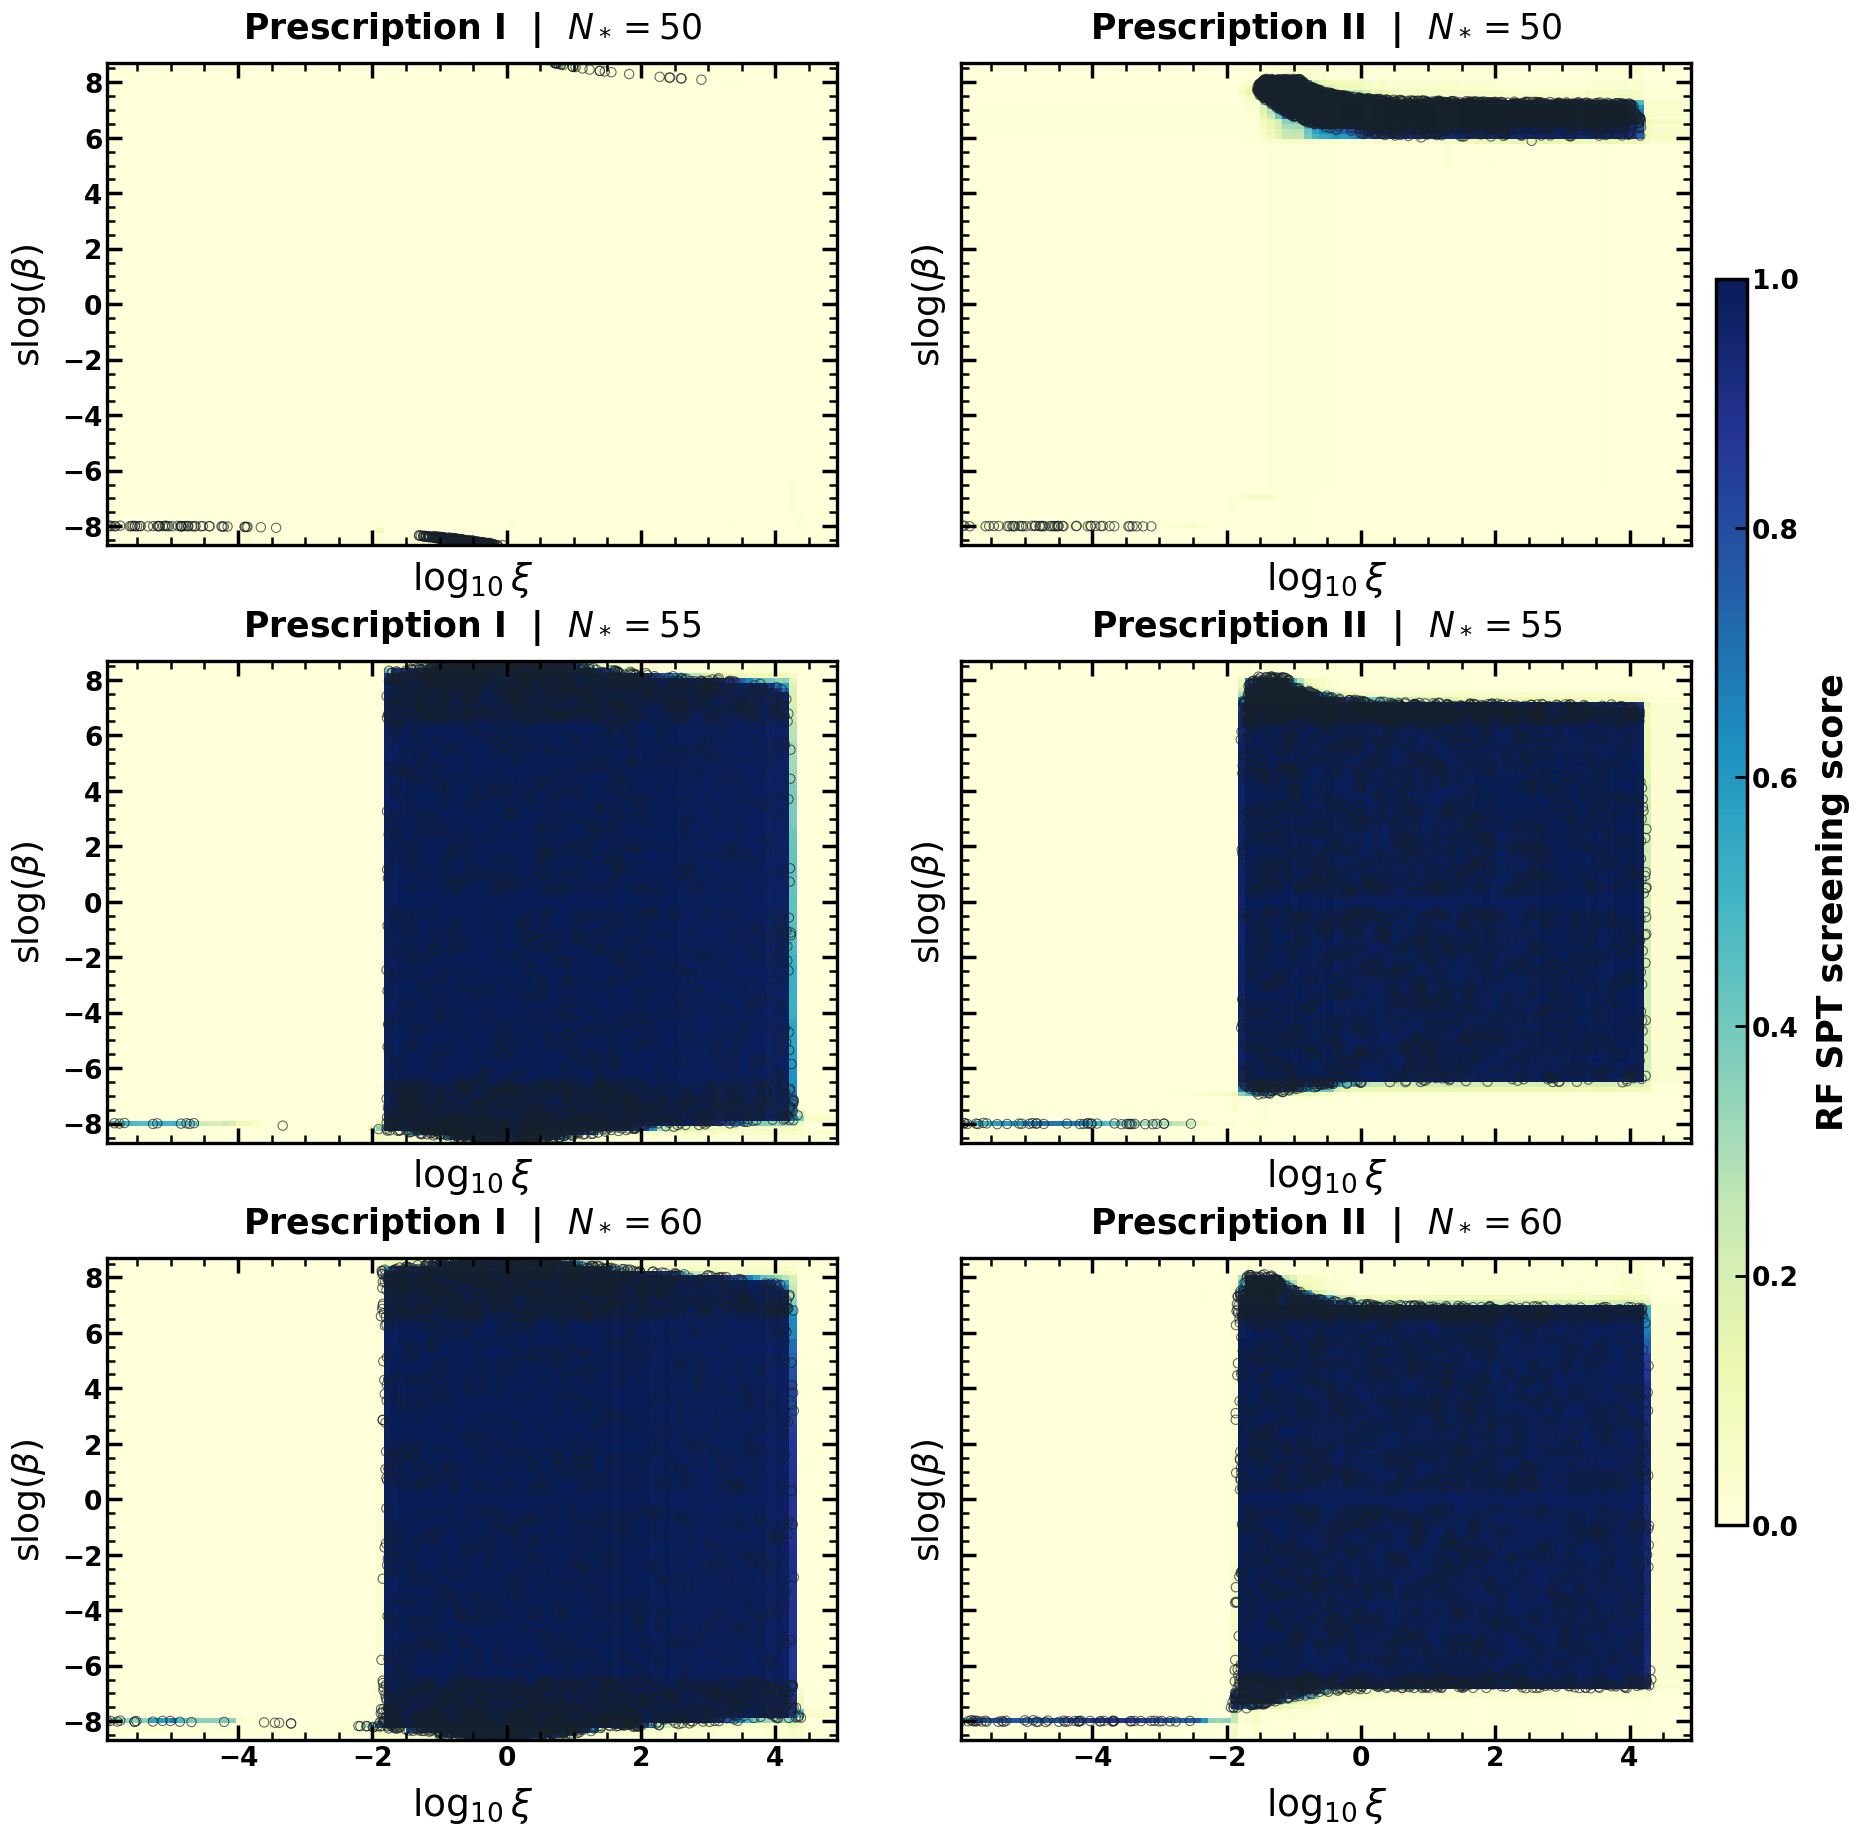

In [11]:
def acceptance_map(band='ACT'):
    if (1,band) not in CLASSIFIERS or (2,band) not in CLASSIFIERS:
        return
    lo_x,hi_x=np.quantile(X.log10_xi,[.005,.995]);lo_y,hi_y=np.quantile(X.signed_log_beta,[.005,.995])
    xx,yy=np.meshgrid(np.linspace(lo_x,hi_x,100),np.linspace(lo_y,hi_y,100))
    fig,axes=plt.subplots(3,2,figsize=(20,19.5),sharex=True,sharey=True)
    plot=None
    for row,nstar in enumerate((50.,55.,60.)):
        grid=pd.DataFrame({'log10_xi':xx.ravel(),'signed_log_beta':yy.ravel(),
                           'N_star':np.full(xx.size,nstar)})
        for col,(p,roman) in enumerate(((1,'I'),(2,'II'))):
            ax=axes[row,col]
            model=CLASSIFIERS[(p,band)]
            pp=model.predict_proba(grid)[:,list(model.classes_).index(1)].reshape(xx.shape)
            plot=ax.pcolormesh(xx,yy,pp,cmap='YlGnBu',vmin=0,vmax=1,shading='auto',rasterized=True)
            flag=f'{band}_any_{roman}'
            eligible=paired.loc[paired[flag] & (paired.N_I-nstar).abs().le(.35)]
            if len(eligible)>3500:eligible=eligible.sample(3500,random_state=SEED)
            if len(eligible):
                mark=feature_matrix(pd.DataFrame({'xi':eligible.xi_I,'beta':eligible.beta_I,'N':eligible.N_I},index=eligible.index))
                ax.scatter(mark.log10_xi,mark.signed_log_beta,s=45,marker='o',
                           facecolors='none',edgecolors='#17212b',linewidths=.75,alpha=.7,
                           rasterized=True,label='Exact accepted inputs')
            axes_for_ml(ax,r'$\log_{10}\xi$',r'$\operatorname{slog}(\beta)$',
                       f'Prescription {roman}  |  $N_*= {int(nstar)}$')
            ax.set_xlim(lo_x,hi_x);ax.set_ylim(lo_y,hi_y)
    fig.subplots_adjust(left=.07,right=.89,bottom=.07,top=.93,hspace=.24,wspace=.17)
    cb=fig.colorbar(plot,ax=axes,fraction=.019,pad=.015,aspect=40)
    cb.set_label(f'RF {band} screening score',fontsize=25,weight='bold',labelpad=12)
    cb.ax.tick_params(length=9,width=2,labelsize=19)
    for lab in cb.ax.get_yticklabels():lab.set_fontweight('bold')
    display_and_save(fig,f'ML_01_{band}_acceptance_by_N')
acceptance_map('ACT')
acceptance_map('SPT')

### Figure ML2 — side-by-side held-out confusion matrices

The left column is Prescription I and the right Prescription II. Rows display ACT and SPT screening results. Matrix entries are **independent input samples** in the held-out test set, never training outcomes or branch counts.

Saved: ML_02_paired_ACT_SPT_confusion.pdf and ML_02_paired_ACT_SPT_confusion.png


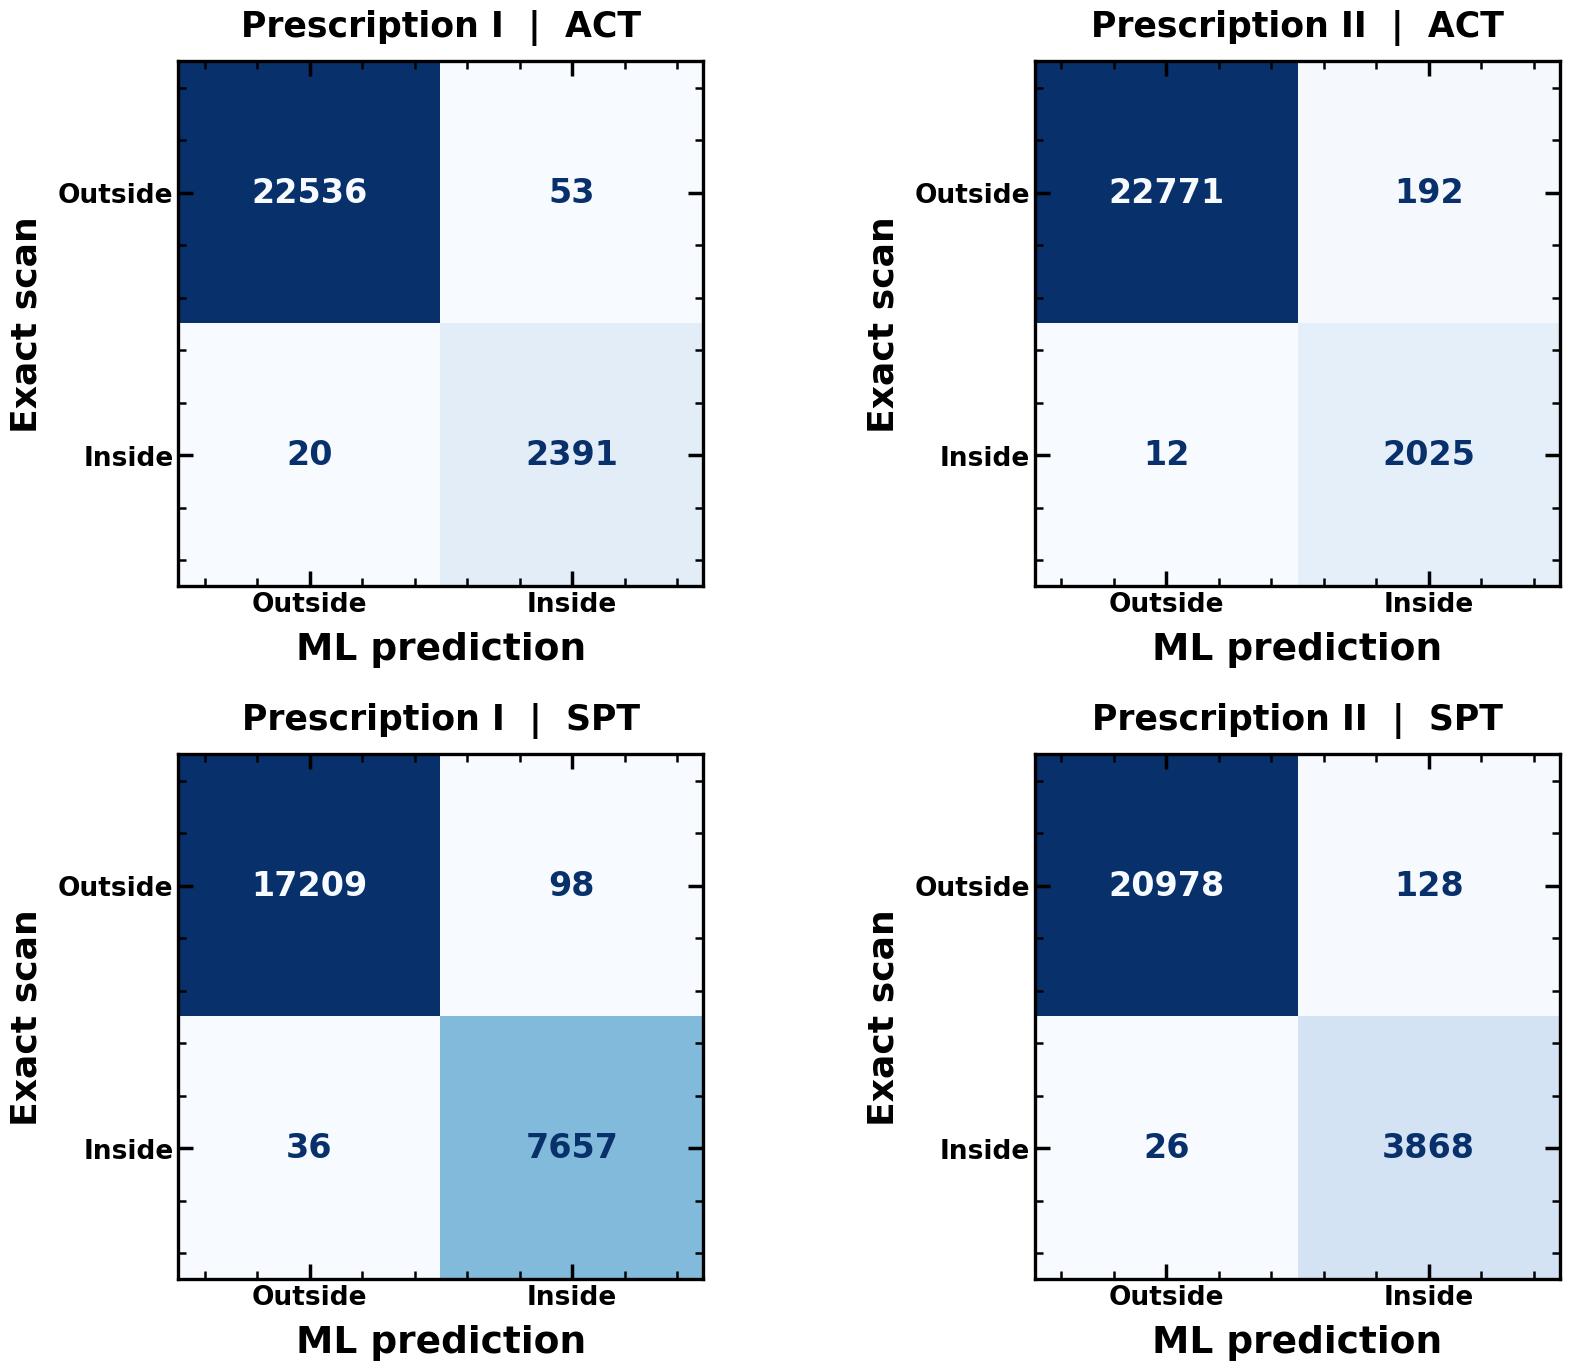

In [12]:
fig,axs=plt.subplots(2,2,figsize=(17,14))
for row,band in enumerate(('ACT','SPT')):
    for col,(p,roman) in enumerate(((1,'I'),(2,'II'))):
        ax=axs[row,col]
        if (p,band) not in HELDOUT:ax.axis('off');continue
        true,pred,prob=HELDOUT[(p,band)]
        mat=confusion_matrix(true,pred,labels=[0,1])
        ConfusionMatrixDisplay(mat,display_labels=['Outside','Inside']).plot(
            ax=ax,cmap='Blues',colorbar=False,values_format='d')
        axes_for_ml(ax,'ML prediction','Exact scan',f'Prescription {roman}  |  {band}')
        for t in ax.texts:t.set_fontsize(24);t.set_fontweight('bold')
fig.subplots_adjust(wspace=.34,hspace=.32,left=.09,right=.97,top=.94,bottom=.07)
display_and_save(fig,'ML_02_paired_ACT_SPT_confusion')

## 6. ML regression: ExtraTrees and MLP for $n_s$, $r$, and $\alpha_s$

A *surrogate model* predicts observables quickly from $(\xi,\beta,N_*)$ and prescription, without evaluating the inflationary equations again. We train **one ExtraTrees regressor and one MLP neural network for each prescription**, and compare them fairly on the same unseen input IDs.

Regression target:
$$\mathbf y=(n_s,\log_{10}\max(r,10^{-30}),\alpha_s).$$
The MLP standardizes features and targets, then minimizes regularized mean square error:
$$\mathcal L_{\rm MLP}=\frac{1}{3m}\sum_{i=1}^m\|\mathbf z_i-\widehat{\mathbf z}_i\|_2^2+\lambda_{\rm L2}\|W\|_2^2.$$

The representative branch selection (smallest $r$ among theory-screened trajectories) is **not guaranteed** to be continuous. Large residuals at branch transitions require exact-solver validation. **ExtraTrees and the MLP are compared; neither is assumed to win.**

In [13]:
def get_reg_frame(p):
    d=representatives[p]
    d=d.loc[d.theory_screen & d.r.gt(0) & np.isfinite(d.alpha_s)].copy()
    return d

def reg_target(d):
    return np.column_stack((d.ns.to_numpy(float),
           np.log10(np.maximum(d.r.to_numpy(float),1e-30)),d.alpha_s.to_numpy(float)))

REG={};REG_STATS=[]
for p,roman in ((1,'I'),(2,'II')):
    frame=get_reg_frame(p)
    tr=frame.loc[frame.sample_id.isin(paired.index[train_ids])].copy()
    te=frame.loc[frame.sample_id.isin(paired.index[test_ids])].copy()
    if len(tr)>REG_MAX_TRAIN_PER_P:tr=tr.sample(REG_MAX_TRAIN_PER_P,random_state=SEED)
    if len(te)>REG_MAX_TEST_PER_P:te=te.sample(REG_MAX_TEST_PER_P,random_state=SEED)
    if len(tr)<80 or len(te)<25:
        print('Too little valid regression data, Prescription',roman);continue
    xtr,xte=feature_matrix(tr),feature_matrix(te)
    ytr,yte=reg_target(tr),reg_target(te)
    models={'ExtraTrees':ExtraTreesRegressor(n_estimators=N_REG_TREES,
            max_depth=22,min_samples_leaf=2,n_jobs=-1,random_state=SEED+p)}
    if RUN_MLP:
        models['MLP']=make_pipeline(StandardScaler(),
             TransformedTargetRegressor(regressor=MLPRegressor(
                hidden_layer_sizes=(64,48),activation='relu',solver='adam',
                alpha=3e-3,batch_size=256,max_iter=220,early_stopping=True,
                n_iter_no_change=16,learning_rate_init=.0015,random_state=SEED+p),
                transformer=StandardScaler()))
    for method,model in models.items():
        with warnings.catch_warnings():
            warnings.simplefilter('ignore',UserWarning)
            model.fit(xtr,ytr)
        yh=model.predict(xte)
        REG[(p,method)]={'model':model,'xte':xte,'yte':yte,'pred':yh,'test':te}
        for j,key in enumerate(('ns','log10r','alpha_s')):
            REG_STATS.append({'prescription':roman,'method':method,'target':key,
                'MAE':mean_absolute_error(yte[:,j],yh[:,j]),
                'RMSE':np.sqrt(mean_squared_error(yte[:,j],yh[:,j])),
                'R2':r2_score(yte[:,j],yh[:,j])})
reg_summary=pd.DataFrame(REG_STATS)
print(reg_summary.to_string(index=False,float_format=lambda v:f'{v:.5g}'))
reg_summary.to_csv(TABLES/'ML_regression_metrics.csv',index=False)

prescription     method  target        MAE       RMSE      R2
           I ExtraTrees      ns 0.00068391  0.0072294 0.98153
           I ExtraTrees  log10r   0.018137    0.17302 0.98532
           I ExtraTrees alpha_s 4.5635e-06 2.0298e-05 0.99045
           I        MLP      ns  0.0025843   0.011432 0.95381
           I        MLP  log10r   0.055582    0.23732 0.97238
           I        MLP alpha_s 1.0638e-05 3.2241e-05 0.97591
          II ExtraTrees      ns  0.0010546  0.0041371 0.99851
          II ExtraTrees  log10r   0.030203    0.11968 0.99773
          II ExtraTrees alpha_s 1.1274e-05 6.1807e-05 0.97884
          II        MLP      ns  0.0041425  0.0088064 0.99326
          II        MLP  log10r   0.099805    0.23501 0.99125
          II        MLP alpha_s  2.788e-05 0.00010425  0.9398


### Figure ML3 — neural-network and tree accuracy, Prescription I versus II

Each model receives **one paired three-row figure**: $n_s$, $\log_{10}r$, and $\alpha_s$ predictions versus exact solutions; the identity line is the reference. **Left: Prescription I; right: Prescription II.** The displayed performance comes from held-out inputs only.

Saved: ML_03_ExtraTrees_paired_regression.pdf and ML_03_ExtraTrees_paired_regression.png


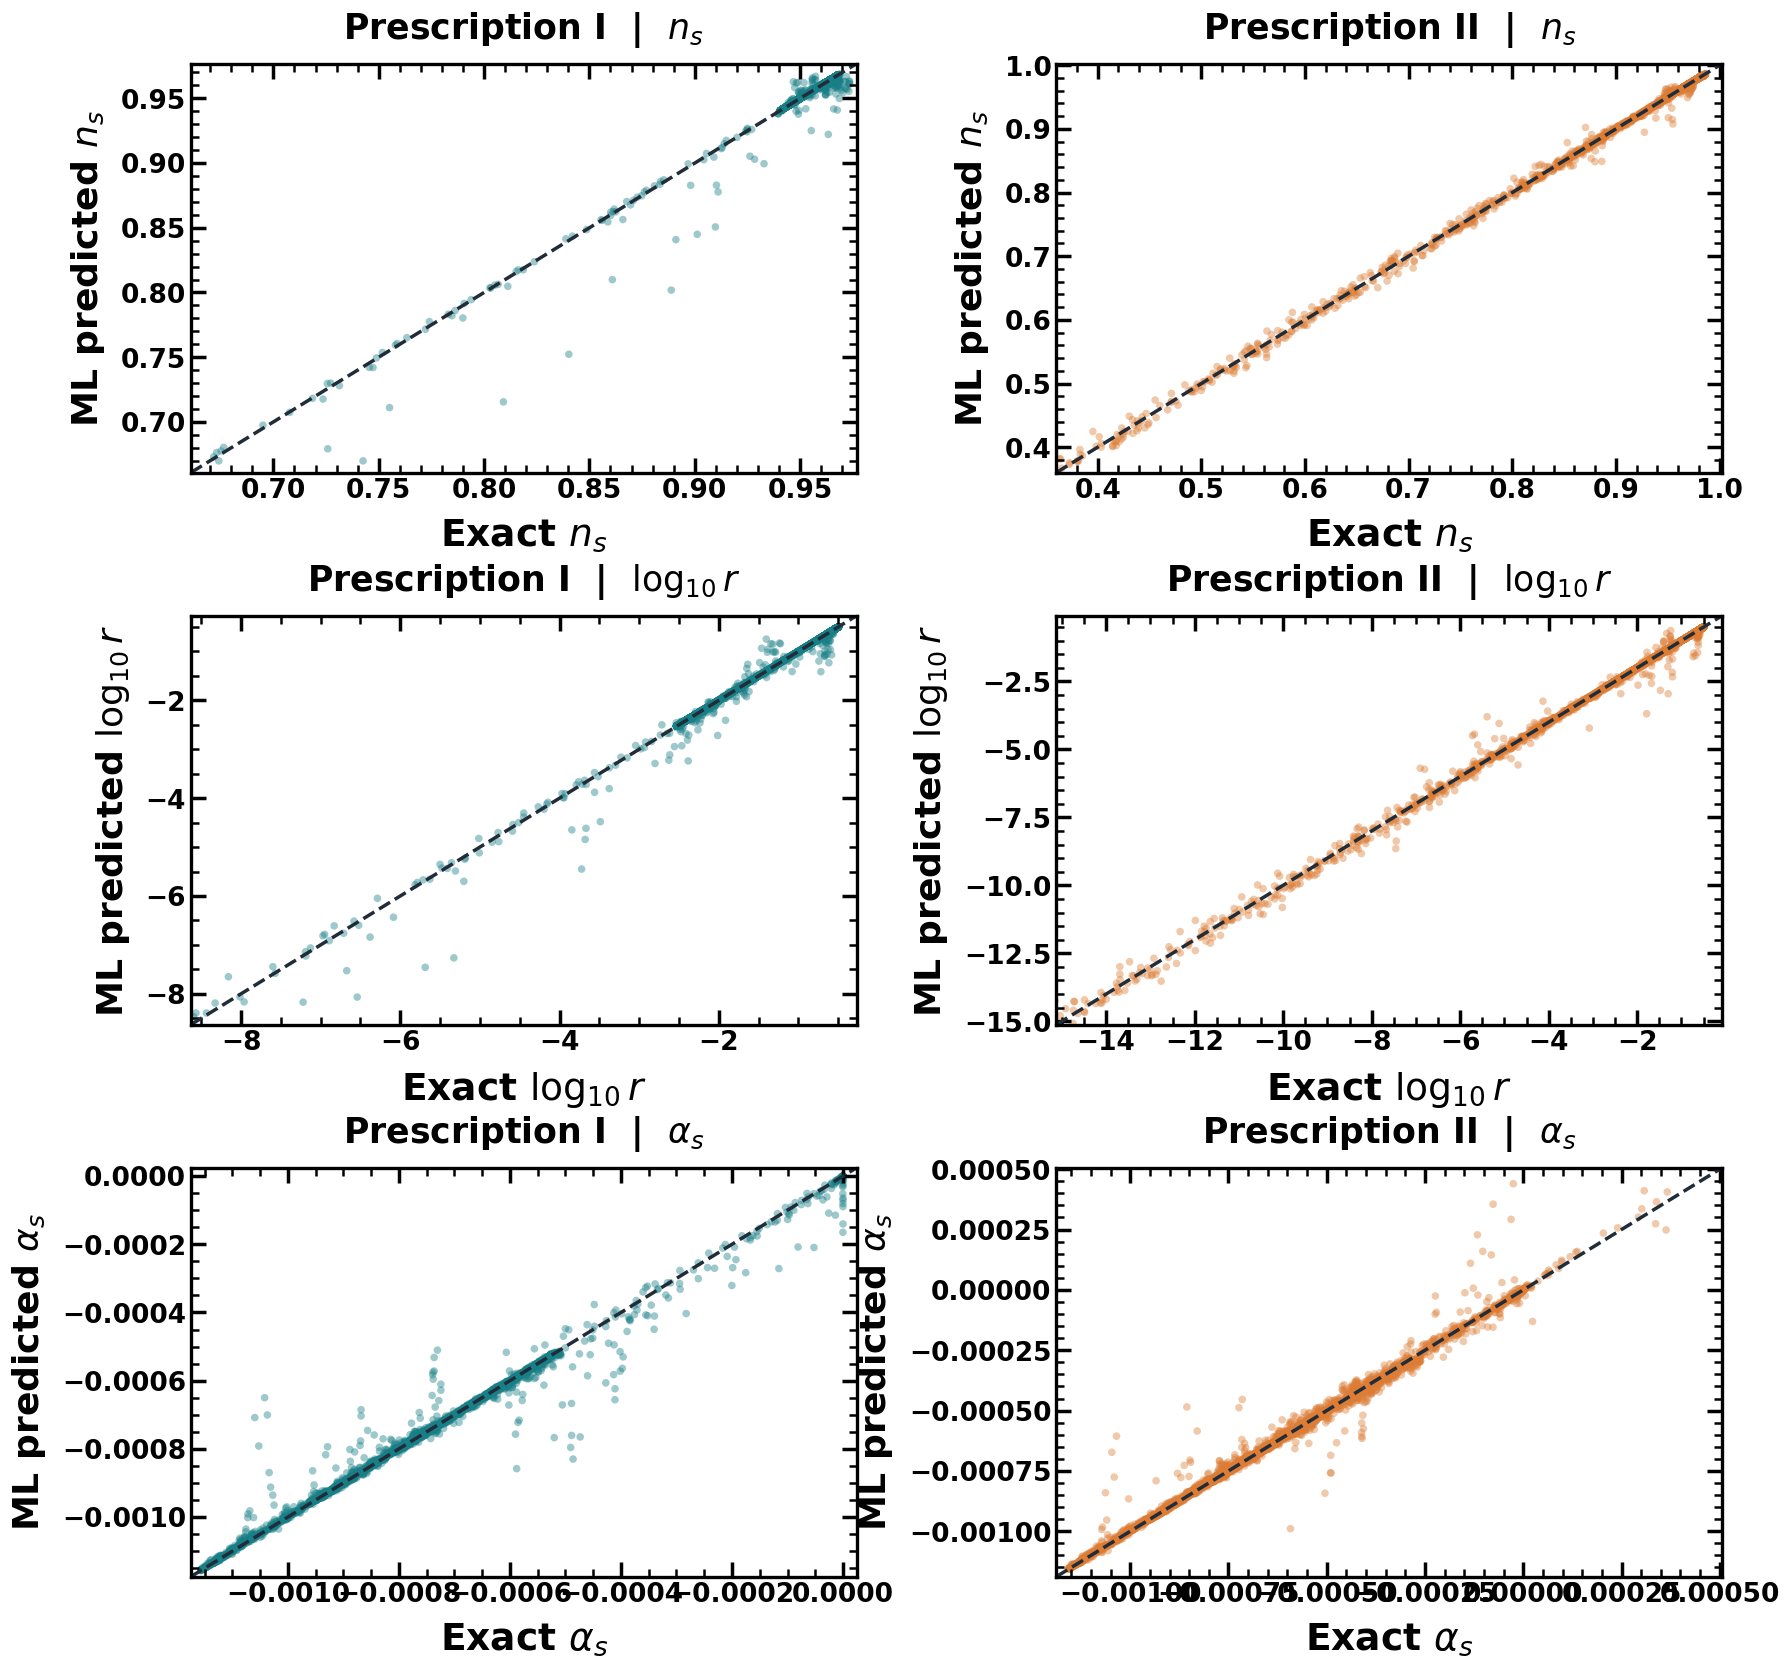

Saved: ML_03_MLP_paired_regression.pdf and ML_03_MLP_paired_regression.png


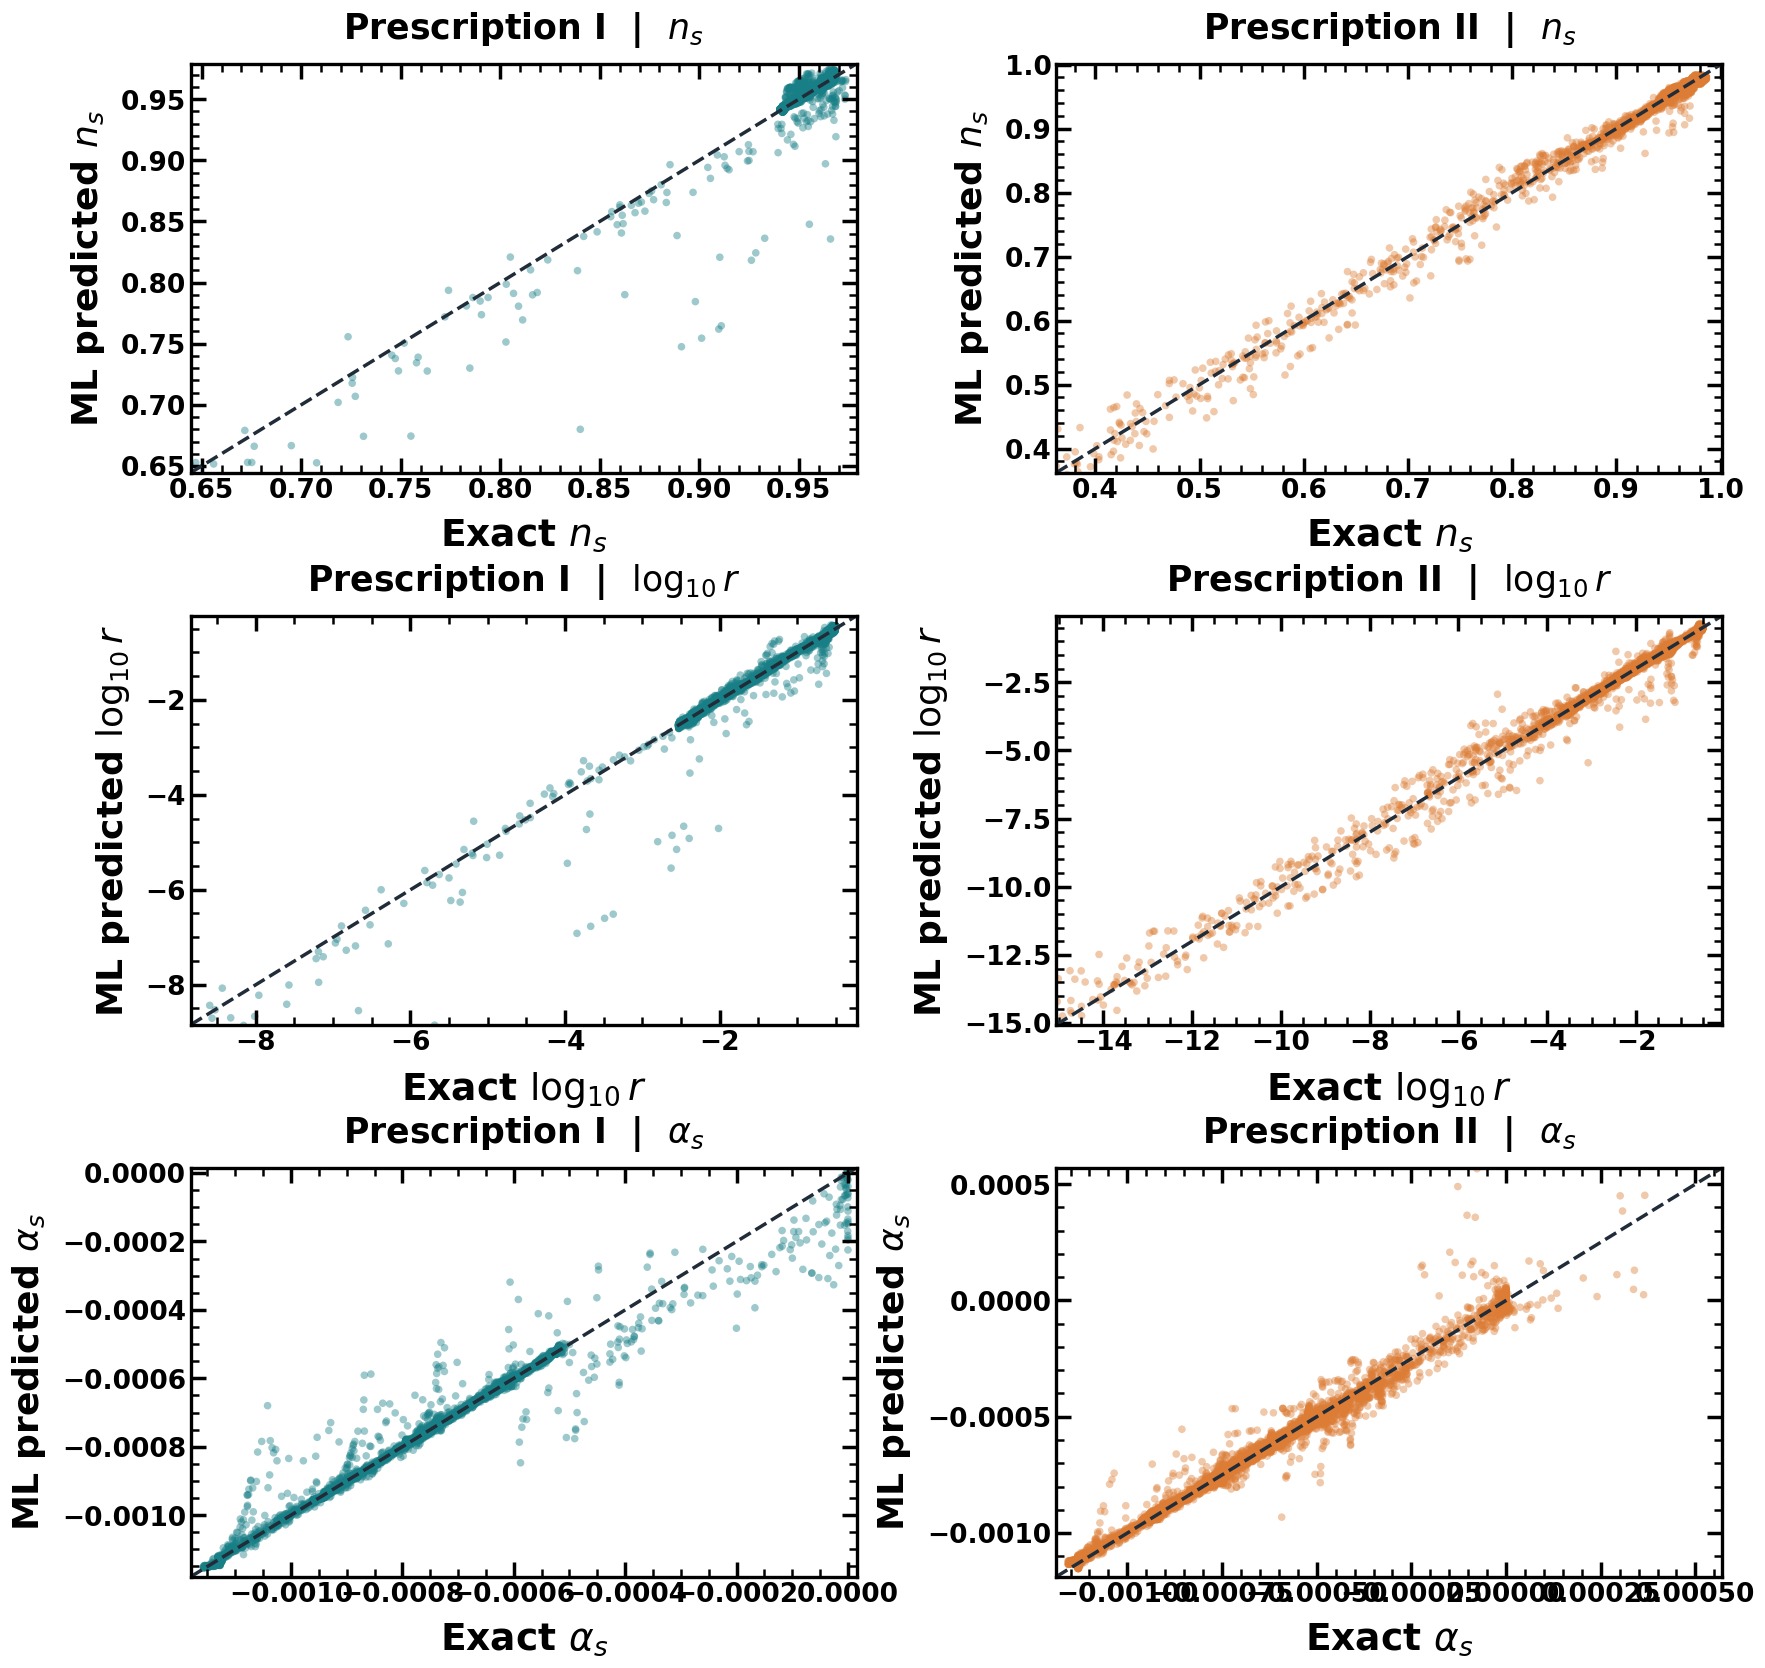

In [14]:
for method in ('ExtraTrees','MLP'):
    if not all((p,method) in REG for p in (1,2)):continue
    fig,axes=plt.subplots(3,2,figsize=(17.5,17),sharex=False,sharey=False)
    for col,(p,roman) in enumerate(((1,'I'),(2,'II'))):
        item=REG[(p,method)]
        for row,label in enumerate((r'$n_s$',r'$\log_{10} r$',r'$\alpha_s$')):
            ax=axes[row,col]
            yy=item['yte'][:,row];pp=item['pred'][:,row]
            finite=np.concatenate((yy[np.isfinite(yy)],pp[np.isfinite(pp)]))
            low,high=np.quantile(finite,[.01,.99]);delta=max((high-low)*.03,1e-6)
            ax.scatter(yy,pp,s=30,alpha=.42,c='#187f86' if p==1 else '#dc7c35',
                       edgecolors='none',rasterized=True)
            ax.plot([low-delta,high+delta],[low-delta,high+delta],ls='--',lw=2.5,color='#212c39')
            ax.set_xlim(low-delta,high+delta);ax.set_ylim(low-delta,high+delta)
            axes_for_ml(ax,'Exact '+label,'ML predicted '+label,
                       f'Prescription {roman}  |  {label}')
    fig.subplots_adjust(left=.095,right=.97,top=.95,bottom=.06,hspace=.35,wspace=.30)
    display_and_save(fig,f'ML_03_{method}_paired_regression')

## 7. Explainable ML: do radiative corrections drive the result?

The signed loop ratio $\beta=\kappa/\lambda$ is a physically motivated input: for positive $\lambda$, positive/negative $\beta$ corresponds to positive/negative effective radiative corrections. **Bosonic and fermionic contributions can compete**, so this sign alone does not uniquely identify a particle species.

We compare the held-out regression performance after independently permuting each input feature:
$$I_j^{(k)}=S_k(X_{\rm test},\mathbf y_{\rm test})-\big\langle S_k(X_{\rm test}^{\pi(j)},\mathbf y_{\rm test})\big\rangle_{\pi},$$
where $S_k=-\operatorname{MAE}(y_k,\widehat y_k)$ for $k=n_s,\log_{10}r,\alpha_s$. Larger $I_j^{(k)}$ indicates that the model **uses** that feature strongly on this scan; it does not prove causality.

We also plot **exact** ACT/SPT acceptance fractions by the sign of $\beta$. Their numerical values depend on the scan design; they are *not posterior odds*.

Saved: ML_04_radiative_permutation_importance.pdf and ML_04_radiative_permutation_importance.png


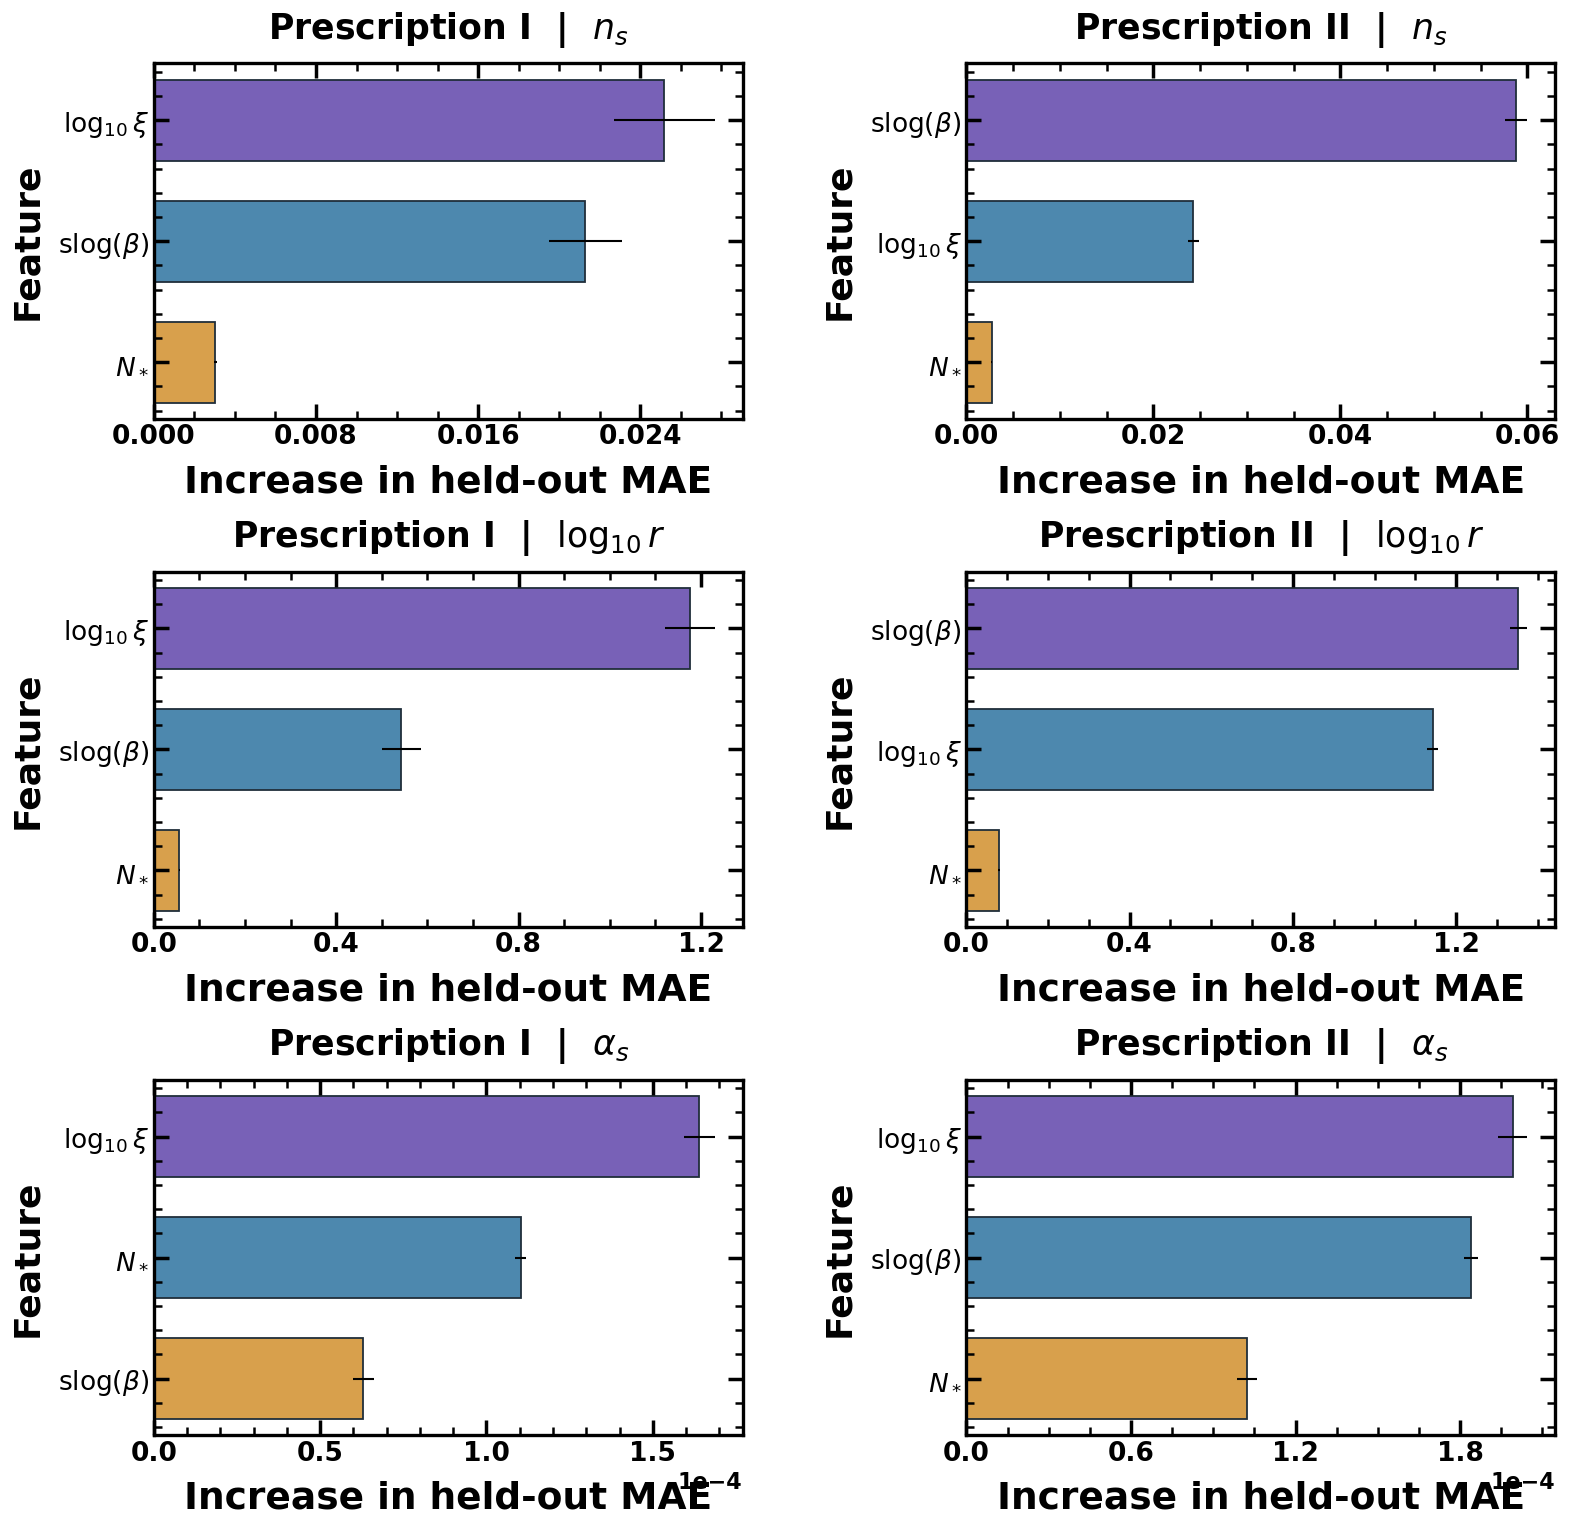

prescription             sign  N_inputs  ACT_rate  SPT_rate
           I Negative $\beta$    150000    0.0974    0.3106
           I Positive $\beta$    149767    0.0930    0.3160
          II Negative $\beta$    149773    0.0267    0.1194
          II Positive $\beta$    150000    0.1392    0.1948
Saved: ML_05_radiative_sign_current_screening.pdf and ML_05_radiative_sign_current_screening.png


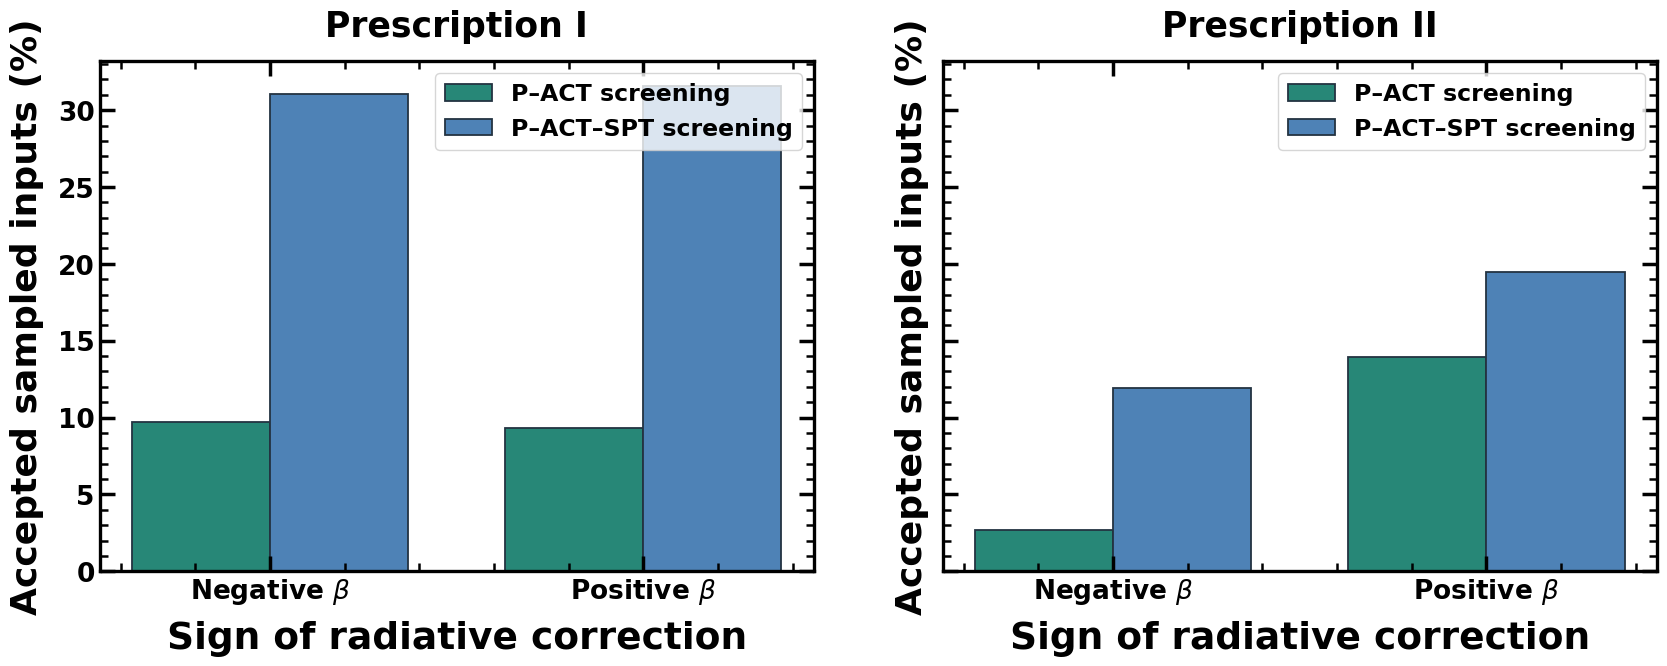

In [15]:
def neg_mae_target(index):
    def fun(estimator,x,y):
        return -mean_absolute_error(y[:,index],estimator.predict(x)[:,index])
    return fun

if all((p,'ExtraTrees') in REG for p in (1,2)):
    fig,axs=plt.subplots(3,2,figsize=(17.3,15.5))
    feat_names={'log10_xi':r'$\log_{10}\xi$',
                'signed_log_beta':r'$\operatorname{slog}(\beta)$',
                'N_star':r'$N_*$'}
    for col,(p,roman) in enumerate(((1,'I'),(2,'II'))):
        z=REG[(p,'ExtraTrees')]
        ix=np.random.default_rng(SEED).choice(len(z['xte']),min(850,len(z['xte'])),replace=False)
        for row,(k,label) in enumerate(((0,r'$n_s$'),(1,r'$\log_{10}r$'),(2,r'$\alpha_s$'))):
            imp=permutation_importance(z['model'],z['xte'].iloc[ix],z['yte'][ix],
                   n_repeats=4,random_state=SEED,n_jobs=1,scoring=neg_mae_target(k))
            ax=axs[row,col]
            order=np.argsort(imp.importances_mean)
            keys=np.array(z['xte'].columns)[order]
            ax.barh(np.arange(len(keys)),imp.importances_mean[order],
                 xerr=imp.importances_std[order],color=['#d8a04c','#4d88ae','#7861b7'],
                 edgecolor='#202e3a',height=.67,linewidth=1.3)
            ax.set_yticks(np.arange(len(keys)),[feat_names[k] for k in keys],fontsize=20)
            axes_for_ml(ax,'Increase in held-out MAE', 'Feature',
                        f'Prescription {roman}  |  {label}')
            from matplotlib.ticker import MaxNLocator
            ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
            if row==2: ax.ticklabel_format(axis='x', style='sci', scilimits=(0,0))
            ax.xaxis.get_offset_text().set_fontsize(16)
            ax.xaxis.get_offset_text().set_fontweight('bold')
    fig.subplots_adjust(left=.17,right=.98,top=.95,bottom=.065,hspace=.43,wspace=.38)
    display_and_save(fig,'ML_04_radiative_permutation_importance')

# Exactly measured input-level fractions, stratified by signed beta.
rows=[]
for p,roman in ((1,'I'),(2,'II')):
    frame=I if p==1 else II
    for name,sel in [('Negative $\\beta$',frame.beta<-1e-12),
                     ('Near zero',frame.beta.abs()<=1e-12),
                     ('Positive $\\beta$',frame.beta>1e-12)]:
        s=frame.loc[sel]
        if not len(s):continue
        rows.append({'prescription':roman,'sign':name,'N_inputs':len(s),
                     'ACT_rate':float(s.ACT_any.mean()),'SPT_rate':float(s.SPT_any.mean())})
RAD_RATE=pd.DataFrame(rows)
RAD_RATE.to_csv(TABLES/'radiative_sign_acceptance.csv',index=False)
print(RAD_RATE.to_string(index=False,float_format=lambda v:f'{v:.4f}'))
fig,axs=plt.subplots(1,2,figsize=(17.5,7.5),sharey=True)
for ax,(p,roman) in zip(axs,((1,'I'),(2,'II'))):
    dd=RAD_RATE.loc[RAD_RATE.prescription.eq(roman)]
    xx=np.arange(len(dd));width=.37
    ax.bar(xx-width/2,dd.ACT_rate.to_numpy()*100,width,color='#278777',
           label='P–ACT screening',edgecolor='#233341',linewidth=1.3)
    ax.bar(xx+width/2,dd.SPT_rate.to_numpy()*100,width,color='#4e82b6',
           label='P–ACT–SPT screening',edgecolor='#233341',linewidth=1.3)
    ax.set_xticks(xx,dd.sign,fontsize=18)
    axes_for_ml(ax,'Sign of radiative correction', 'Accepted sampled inputs (%)',
                f'Prescription {roman}')
    ax.legend(fontsize=17,prop={'weight':'bold','size':17},loc='upper right')
fig.subplots_adjust(left=.09,right=.98,top=.88,bottom=.20,wspace=.18)
display_and_save(fig,'ML_05_radiative_sign_current_screening')

## 8. Future CMB $B$-mode sensitivity: which predictions can be measured?

**Forecasts, not detections.** We compare model predictions with illustrative *Gaussian* $1\sigma$ uncertainties in $r$:

| Scenario | $\sigma_r$ used | Status/source |
|---|---:|---|
| Simons Observatory expanded SAT, baseline | $0.0012$ | 2026 JCAP forecast, conditional on noise/foregrounds and delensing |
| Simons Observatory expanded SAT, optimistic | $0.0007$ | 2026 JCAP optimistic forecast |
| South Pole Observatory | $0.0010$ | Approximate 2026 outlook for mid-2030s |
| LiteBIRD revised total requirement | $0.0020$ | **Updated 2026 mission requirement**, including systematics and contingency; the lower statistical target is not interchangeable with this total uncertainty |
| CMB-S4 | $0.0010$ | **Historical design comparison only**: original funding was withdrawn in 2025 |

Useful sources: [SO forecast (JCAP 2026)](https://doi.org/10.1088/1475-7516/2026/04/051), [LiteBIRD post-reformation mission (2026)](https://arxiv.org/abs/2607.25285), [SPO/BICEP 2026 outlook](https://indico.fnal.gov/event/72820/contributions/341034/), [CMB-S4 official project status](https://cmb-s4.org/).

For an *idealized Gaussian estimate only*, $Z_{\rm det}\equiv r/\sigma_r$. An input with $Z_{\rm det}\ge3$ or $5$ has a model $r$ above the corresponding nominal threshold; a real detection also depends on foregrounds, systematics, lensing, physical boundaries and a full experiment likelihood. The point-count fraction below is conditional on the screening cuts and branch-selection convention, **not a probability of detection**.

Saved: Future_01_paired_r_sensitivity.pdf and Future_01_paired_r_sensitivity.png


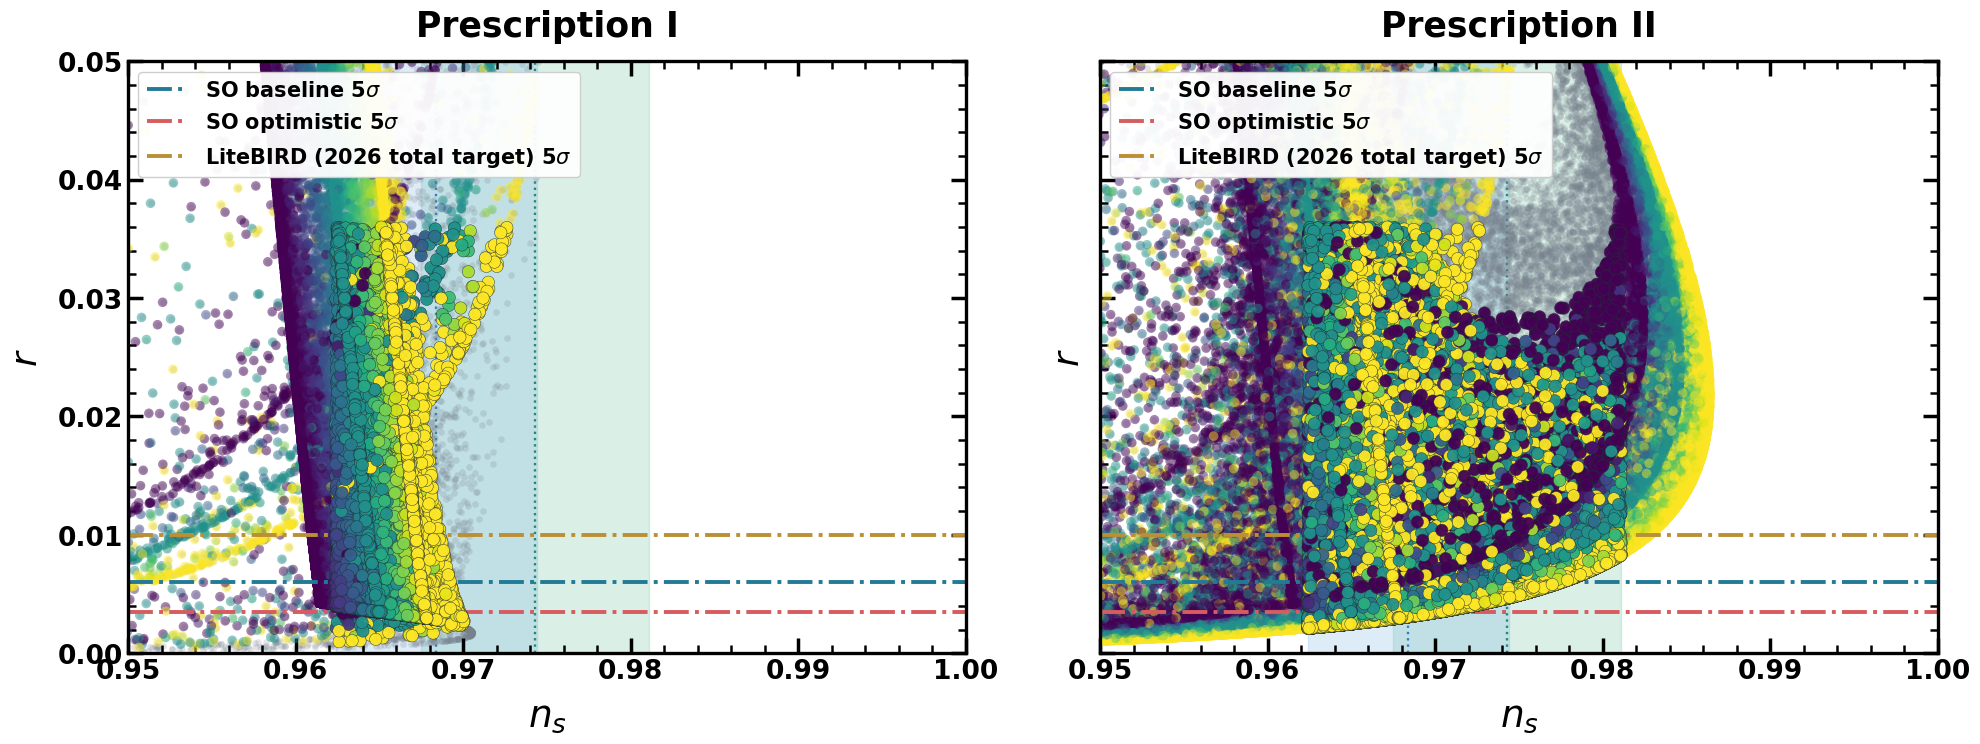

prescription                     scenario  sigma_r  N_accepted_inputs  fraction_above_3sigma  fraction_above_5sigma
           I                  SO baseline   0.0012              93922                 0.5021                 0.2103
           I                SO optimistic   0.0007              93922                 0.9997                 0.6297
           I       South Pole Observatory   0.0010              93922                 0.8644                 0.2562
           I LiteBIRD (2026 total target)   0.0020              93922                 0.2103                 0.1279
           I     CMB-S4 (historical only)   0.0010              93922                 0.8644                 0.2562
          II                  SO baseline   0.0012              53534                 0.6856                 0.4095
          II                SO optimistic   0.0007              53534                 1.0000                 0.7531
          II       South Pole Observatory   0.0010              53534   

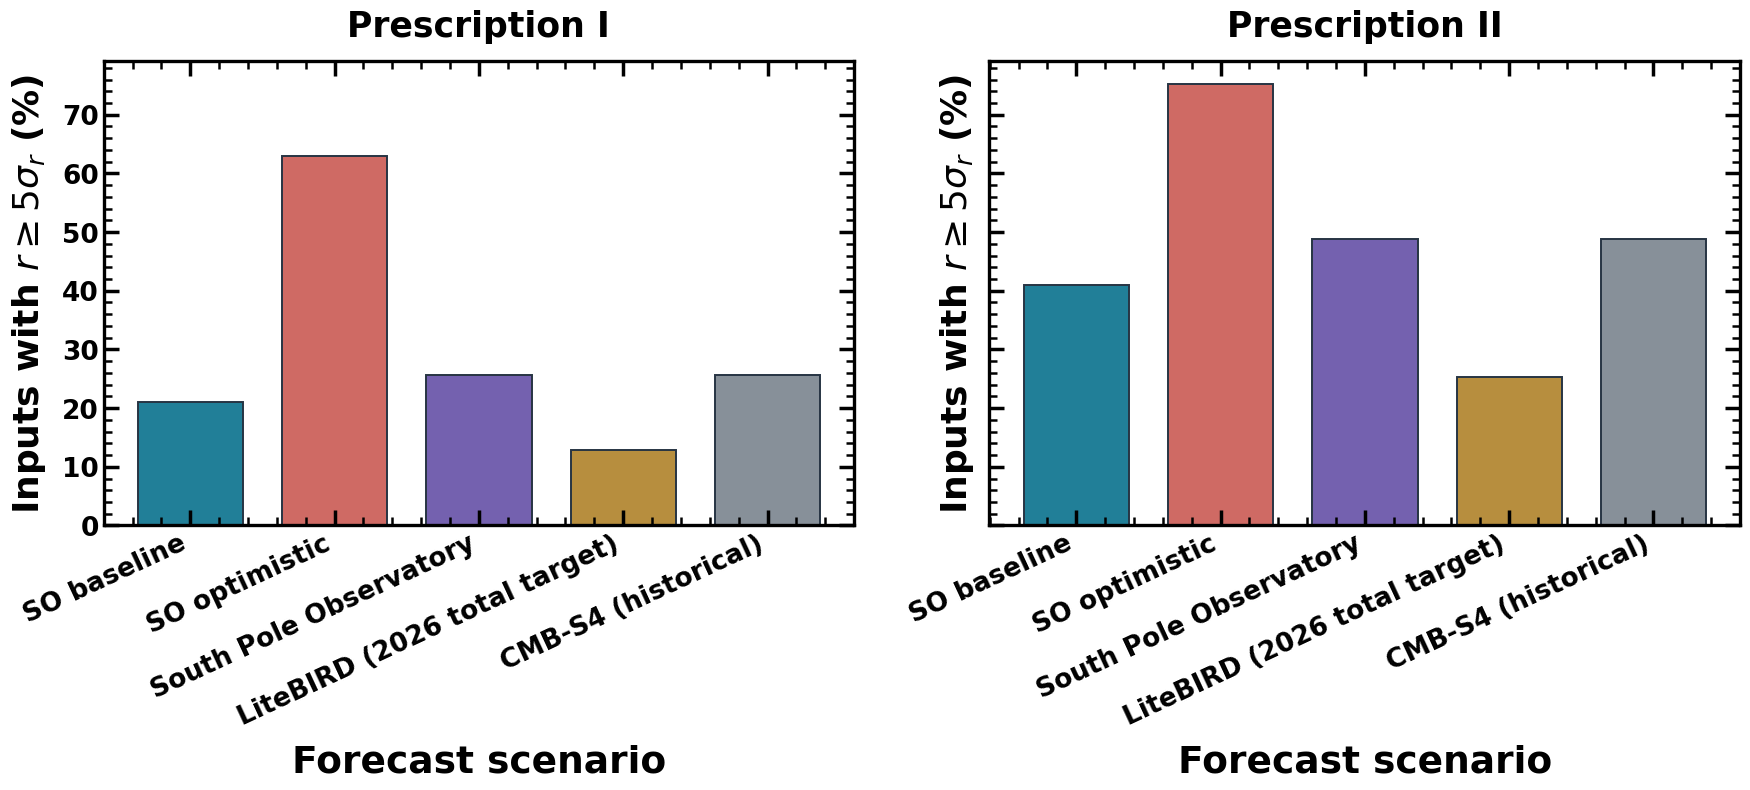

In [16]:
FUTURE_R={
 'SO baseline':(.0012,'#227b96'),
 'SO optimistic':(.0007,'#d65c60'),
 'South Pole Observatory':(.0010,'#7562ac'),
 'LiteBIRD (2026 total target)':(.0020,'#bb8f35'),
 'CMB-S4 (historical only)':(.0010,'#7c858e')}

# One representative branch per accepted input (smallest r): avoid branch-multiplicity bias.
FUTURE_INPUT={}
for p in (1,2):
    d=DATA[p].loc[DATA[p].ACT95 | DATA[p].SPT95].copy()
    FUTURE_INPUT[p]=d.sort_values(['sample_id','r']).drop_duplicates('sample_id')

if RUN_FUTURE_FORECAST:
    fig,axs=plt.subplots(1,2,figsize=(20.0,8.0),sharex=True,sharey=True)
    for ax,(p,roman) in zip(axs,((1,'I'),(2,'II'))):
        d=DATA[p]
        ns_bands(ax,'x')
        draw_scan_points(ax,d,'ns','r')
        for name in ['SO baseline','SO optimistic','LiteBIRD (2026 total target)']:
            sig,c=FUTURE_R[name]
            ax.axhline(5*sig,ls='-.',lw=2.8,color=c,label=f'{name} 5$\\sigma$')
        ax.set_xlim(.95,1);ax.set_ylim(0,.05)
        axes_for_ml(ax,r'$n_s$',r'$r$',f'Prescription {roman}')
        ax.legend(loc='upper left',prop={'size':15,'weight':'bold'},framealpha=.95)
    fig.subplots_adjust(left=.075,right=.98,bottom=.14,top=.88,wspace=.16)
    display_and_save(fig,'Future_01_paired_r_sensitivity')

    rows=[]
    for p,roman in ((1,'I'),(2,'II')):
        d=FUTURE_INPUT[p]
        for name,(sig,c) in FUTURE_R.items():
            rows.append({'prescription':roman,'scenario':name,'sigma_r':sig,'N_accepted_inputs':len(d),
                'fraction_above_3sigma':float((d.r>=3*sig).mean()) if len(d) else np.nan,
                'fraction_above_5sigma':float((d.r>=5*sig).mean()) if len(d) else np.nan})
    future_table=pd.DataFrame(rows)
    future_table.to_csv(TABLES/'future_r_threshold_table.csv',index=False)
    print(future_table.to_string(index=False,float_format=lambda v:f'{v:.4f}'))
    fig,axs=plt.subplots(1,2,figsize=(18.6,8.0),sharey=True)
    for ax,(p,roman) in zip(axs,((1,'I'),(2,'II'))):
        d=future_table.loc[future_table.prescription.eq(roman)]
        names=d.scenario.str.replace(' (historical only)',' (historical)',regex=False).tolist()
        x=np.arange(len(d))
        ax.bar(x,d.fraction_above_5sigma*100,color=['#217f98','#cf6a64','#7461af','#b78e3e','#879099'],
               edgecolor='#273443',linewidth=1.4,width=.73)
        ax.set_xticks(x,names,rotation=25,ha='right',fontsize=16)
        axes_for_ml(ax,'Forecast scenario',r'Inputs with $r\geq5\sigma_r$ (%)',f'Prescription {roman}')
    fig.subplots_adjust(left=.10,right=.98,bottom=.28,top=.86,wspace=.18)
    display_and_save(fig,'Future_02_paired_5sigma_threshold_fractions')

## 9. Conditional mock-measurement test: which $r$ would *appear* more compatible?

To answer "what measurement might distinguish them?" more directly, we construct a **deliberately simplified, scan-dependent conditional predictive score**, not evidence from ACT or a real forecast posterior.

Let $\{r_{P,i}\}$ be the representative tensor predictions of input combinations passing the chosen current screen for prescription $P$. **Assuming equal weights per sampled input**, a hypothetical Gaussian measurement $r_{\rm obs}$ with uncertainty $\sigma_r$ gives
$$\widetilde{Z}_{P}(r_{\rm obs}\mid\mathrm{screen})=\frac{1}{m_P}\sum_{i=1}^{m_P}\exp\!\left[-\frac{(r_{\rm obs}-r_{P,i})^2}{2\sigma_r^2}\right],\qquad\mathcal{R}=\ln\frac{\widetilde Z_{II}}{\widetilde Z_I}.$$

*Positive* $\mathcal R$ means the simulated result lies closer to the **conditional sampled** Prescription II distribution; *negative* means closer to I. **It is not a Bayes factor**: the scan is not a physically justified prior, conditioning drops model acceptance factors, and branch weights are chosen conventionally. Crucially, each prescription may retune parameters independently; fixed-input $\Delta r$ plots cannot establish model discrimination.

We show this toy score both under **current ACT** and **current SPT** spectral screens at the published Simons Observatory baseline $\sigma_r=0.0012$.

Saved: Future_03_toy_conditional_r_comparison.pdf and Future_03_toy_conditional_r_comparison.png


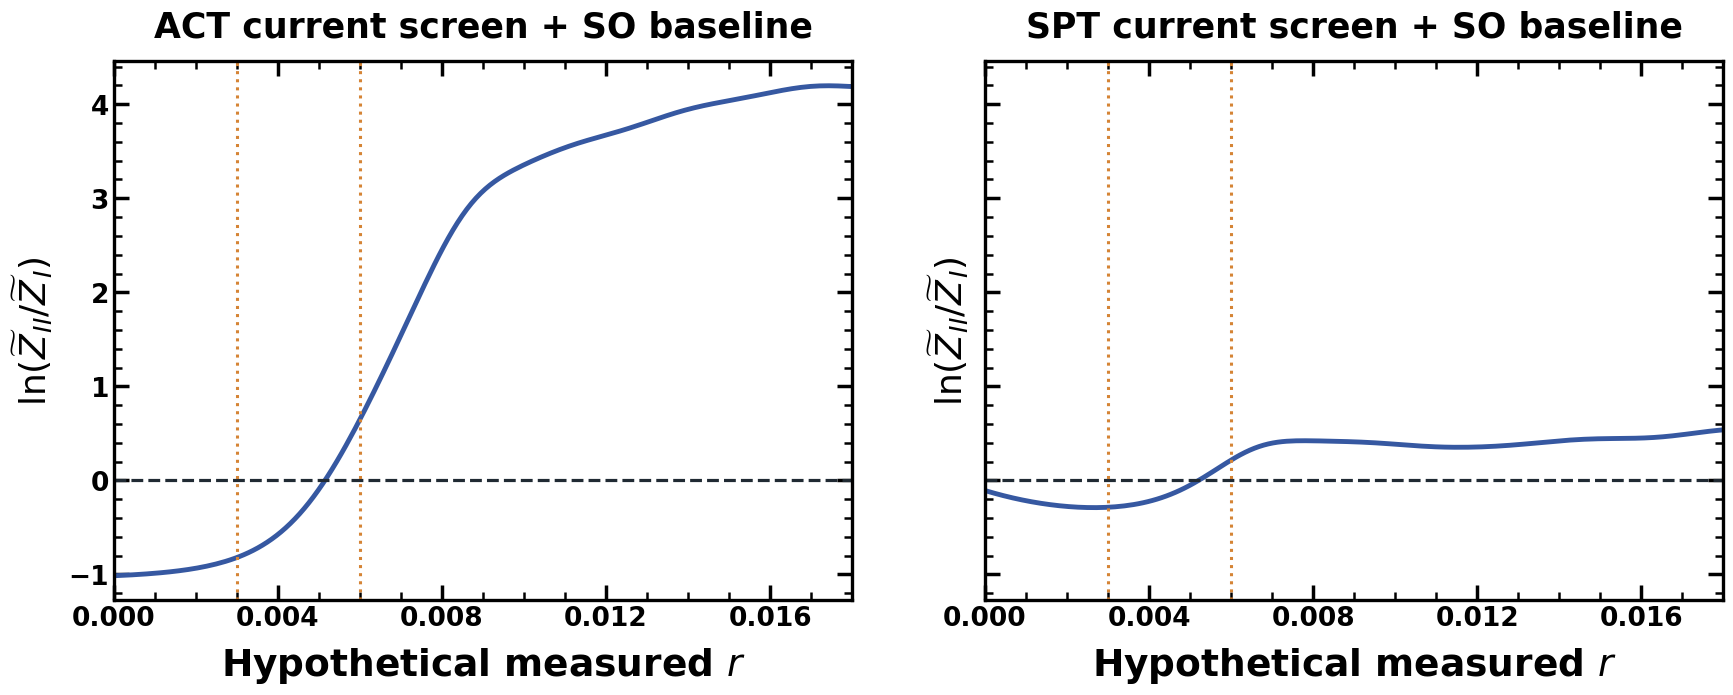

In [17]:
if RUN_FUTURE_FORECAST:
    sigma=.0012
    observed=np.linspace(0,.018,160)
    fig,axs=plt.subplots(1,2,figsize=(18.5,7.7),sharey=True)
    rows=[]
    for ax,band in zip(axs,('ACT','SPT')):
        models={}
        for p in (1,2):
            flag=f'{band}95'
            d=DATA[p].loc[DATA[p][flag]].copy()
            d=d.sort_values(['sample_id','r']).drop_duplicates('sample_id')
            rr=d.r.to_numpy(float)
            # deterministic limit only for plotting speed; equal row weights within available sample
            if len(rr)>25000:
                rr=np.random.default_rng(SEED+p).choice(rr,25000,replace=False)
            models[p]=rr
        if any(len(models[p])<20 for p in (1,2)):
            ax.text(.1,.5,'Insufficient screened data',transform=ax.transAxes)
            continue
        v=[]
        for robs in observed:
            a=logsumexp(-.5*((models[1]-robs)/sigma)**2)-np.log(len(models[1]))
            b=logsumexp(-.5*((models[2]-robs)/sigma)**2)-np.log(len(models[2]))
            v.append(b-a)
            rows.append({'screen':band,'r_observed_hypothetical':robs,'log_conditional_ratio_II_over_I':b-a})
        ax.plot(observed,v,lw=3.5,color='#3658a1')
        ax.axhline(0,ls='--',color='#202a33',lw=2.3)
        ax.axvline(0.003,ls=':',color='#d58435',lw=2.2)
        ax.axvline(0.006,ls=':',color='#d58435',lw=2.2)
        axes_for_ml(ax,r'Hypothetical measured $r$',r'$\ln(\widetilde Z_{II}/\widetilde Z_I)$',
                    f'{band} current screen + SO baseline')
        from matplotlib.ticker import MaxNLocator
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.set_xlim(0,.018)
    fig.subplots_adjust(left=.10,right=.97,bottom=.16,top=.86,wspace=.18)
    display_and_save(fig,'Future_03_toy_conditional_r_comparison')
    pd.DataFrame(rows).to_csv(TABLES/'future_mock_r_conditional_scores.csv',index=False)

## 10. ML-assisted future tensor threshold: does the surrogate reproduce the exact $r$ result?

Before accelerating a future scan with ML, verify that its predicted tensor amplitude is accurate **near each experimental threshold**, not merely in overall $R^2$. The chart below compares held-out $r/\sigma_r$ from the exact numerical solution and the ExtraTrees surrogate, alongside a paired confusion matrix for the test $r\ge5\sigma_r$ using the **SO baseline**. Left = Prescription I; right = Prescription II.

Because the ML model is only an interpolation tool, **new physical discoveries and all results close to a decision boundary must be checked with the exact solver**.

Saved: ML_06_future_r_surrogate_threshold_validation.pdf and ML_06_future_r_surrogate_threshold_validation.png


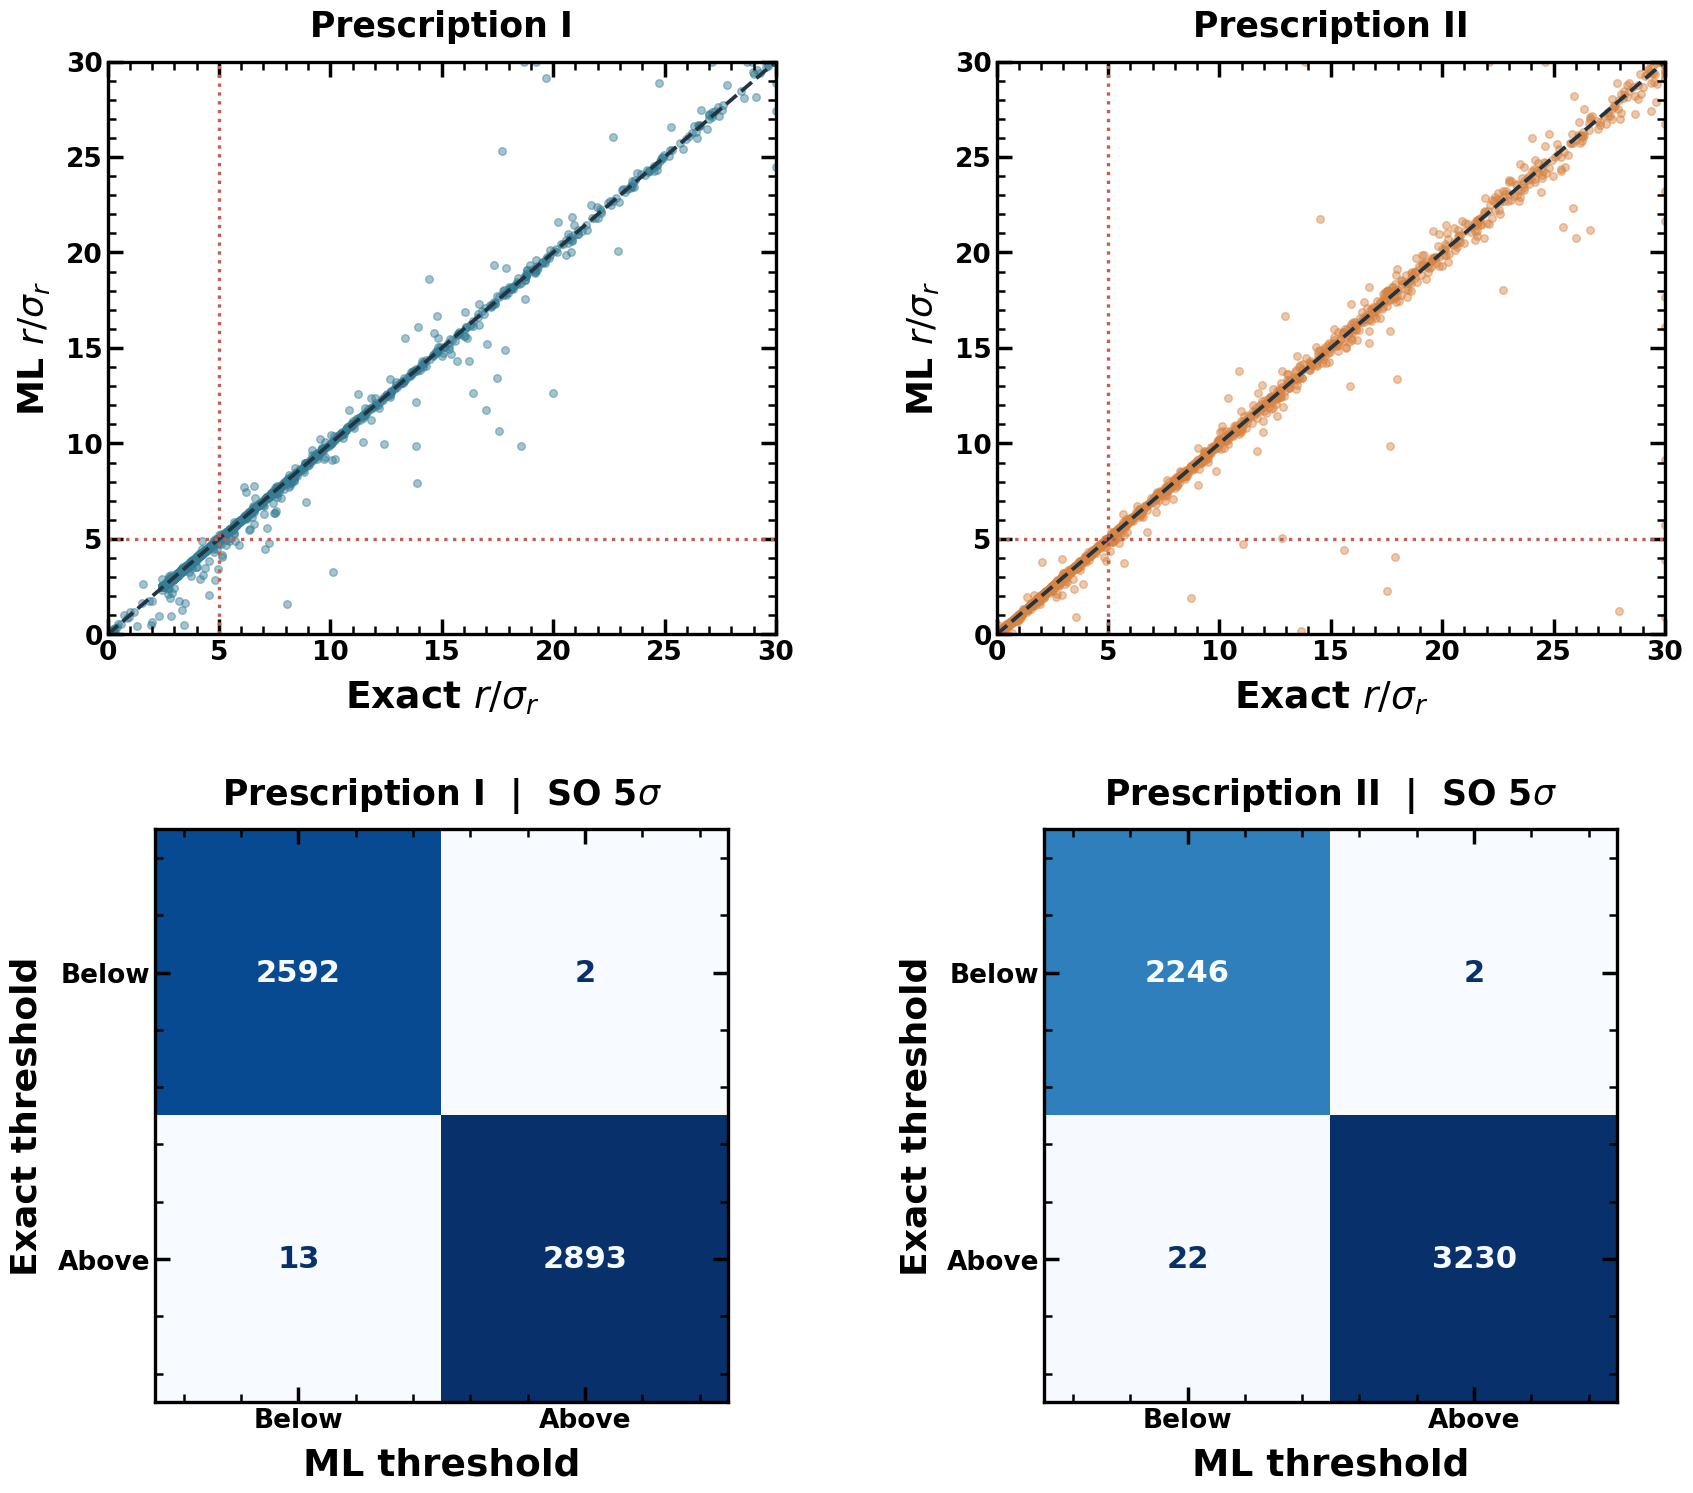

In [18]:
if RUN_FUTURE_FORECAST and all((p,'ExtraTrees') in REG for p in (1,2)):
    fig,axs=plt.subplots(2,2,figsize=(17.5,15.5))
    sig=FUTURE_R['SO baseline'][0]
    for col,(p,roman) in enumerate(((1,'I'),(2,'II'))):
        item=REG[(p,'ExtraTrees')]
        exact=np.power(10,item['yte'][:,1]); approx=np.power(10,np.clip(item['pred'][:,1],-30,0))
        ax=axs[0,col]
        a=np.minimum(exact/sig,30);b=np.minimum(approx/sig,30)
        ax.scatter(a,b,s=30,alpha=.45,color='#347d95' if p==1 else '#d68444',rasterized=True)
        ax.plot([0,30],[0,30],ls='--',lw=2.7,color='#223341')
        ax.axvline(5,ls=':',lw=2.4,color='#c35f50');ax.axhline(5,ls=':',lw=2.4,color='#c35f50')
        ax.set_xlim(0,30);ax.set_ylim(0,30)
        axes_for_ml(ax,r'Exact $r/\sigma_r$',r'ML $r/\sigma_r$',f'Prescription {roman}')
        ax=axs[1,col]
        ytrue=(exact>=5*sig).astype(int);ypred=(approx>=5*sig).astype(int)
        ConfusionMatrixDisplay(confusion_matrix(ytrue,ypred,labels=[0,1]),
            display_labels=['Below','Above']).plot(ax=ax,cmap='Blues',colorbar=False,values_format='d')
        axes_for_ml(ax,'ML threshold','Exact threshold',f'Prescription {roman}  |  SO 5$\\sigma$')
        for t in ax.texts:t.set_fontsize(22);t.set_fontweight('bold')
    fig.subplots_adjust(left=.09,right=.98,bottom=.075,top=.94,hspace=.34,wspace=.33)
    display_and_save(fig,'ML_06_future_r_surrogate_threshold_validation')

## 11. Interpretation and reproducibility

**Current experiments:** Random Forest maps tell us *which inputs* tend to pass the adopted ACT or SPT **rectangular screening**, not which prescription is fundamentally true. ExtraTrees and MLP show whether nonlinear regression can interpolate numerical observables at held-out points. Feature importance and signed-$\beta$ grouping address the role of **radiative corrections** within the numerical scan.

**Future experiments:** The $3\sigma/5\sigma$ reach plots show conditional detectability under specified $\sigma_r$ scenarios. The mock-$r$ curves go one step further by asking which conditional prediction distribution a *hypothetical* measurement resembles, but do **not** calculate robust model evidence. For a submission-level claim of preference, replace all simple screens by the full joint $(n_s,r,\alpha_s)$ likelihood, specify the underlying prior, marginalize consistently over the continuous parameters and permitted branches, and rerun any ML-selected point through the exact solver.

**Novelty direction without active learning:** Present the combination of (i) two prescription-wide exact scans, (ii) feature-level analysis of the radiative ratio, (iii) cross-validated ML surrogates, and (iv) explicit model-conditioned *future tensor sensitivities*. Machine learning is a *scientific instrument*, not the model-selection criterion.

**References / scenario provenance:**
1. Planck Collaboration, *Planck 2018 results. X. Constraints on inflation*, A&A **641** (2020) A10, arXiv:1807.06211.
2. BICEP/Keck Collaboration, *Improved Constraints on Primordial Gravitational Waves*, PRL **127** (2021) 151301, arXiv:2110.00483.
3. Abril-Cabezas *et al.*, SO expanded-SAT forecast, JCAP **04** (2026) 051, https://doi.org/10.1088/1475-7516/2026/04/051.
4. LiteBIRD Collaboration, *LiteBIRD Mission Overview after Mission Reformation* (2026), arXiv:2607.25285; revised total uncertainty $\delta r<0.002$ (68% CL).
5. DPF 2026 BICEP/South Pole Observatory outlook: https://indico.fnal.gov/event/72820/contributions/341034/.
6. CMB-S4 official shutdown information: https://cmb-s4.org/ (July 2025).
7. Breiman, *Random Forests*, Machine Learning **45** (2001) 5.
8. Geurts, Ernst, and Wehenkel, *Extremely randomized trees*, Machine Learning **63** (2006) 3.
9. Pedregosa *et al.*, *Scikit-learn: Machine Learning in Python*, JMLR **12** (2011) 2825.

In [19]:
from collections import Counter
pdfs=sorted(FIGS.glob('*.pdf'))
print('\nINPUT MODE:', 'REFERENCE PREVIEW (8,087 earlier branches)' if IS_PREVIEW else 'YOUR USER SCAN')
print('Generated PDF figures:',len(pdfs))
for f in pdfs:print(' ',f.name)
print('\nSaved data tables:')
for f in sorted(TABLES.glob('*.csv')):print(' ',f.name)
print('\nFor the completed large scan, place Prescription_I_ALL.dat and Prescription_II_ALL.dat inside data/ and Run All.')


INPUT MODE: YOUR USER SCAN
Generated PDF figures: 16
  Fig_01_ns_r.pdf
  Fig_02_kappa_ns.pdf
  Fig_03_lambda_ns.pdf
  Fig_04_alpha_ns.pdf
  Fig_05_xi_ns.pdf
  Future_01_paired_r_sensitivity.pdf
  Future_02_paired_5sigma_threshold_fractions.pdf
  Future_03_toy_conditional_r_comparison.pdf
  ML_01_ACT_acceptance_by_N.pdf
  ML_01_SPT_acceptance_by_N.pdf
  ML_02_paired_ACT_SPT_confusion.pdf
  ML_03_ExtraTrees_paired_regression.pdf
  ML_03_MLP_paired_regression.pdf
  ML_04_radiative_permutation_importance.pdf
  ML_05_radiative_sign_current_screening.pdf
  ML_06_future_r_surrogate_threshold_validation.pdf

Saved data tables:
  future_mock_r_conditional_scores.csv
  future_r_threshold_table.csv
  matched_input_flags.csv
  ML_classification_metrics.csv
  ML_regression_metrics.csv
  radiative_sign_acceptance.csv
  representative_branches_1.csv
  representative_branches_2.csv

For the completed large scan, place Prescription_I_ALL.dat and Prescription_II_ALL.dat inside data/ and Run All.
